# 2026 年中国研究生数学建模竞赛 F 题 · 问题四
## 技术演进分析与前沿预测 —— 算力归因、双时间轴、增量桥接与多期限样本外验证

> **本版原则**：问题四采用统一的当前模型链条。所有结论均由当前数据、当前模型和样本外验证直接产生，并针对评审指出的逻辑缺口进行结构化修正。

### 本版的四条核心逻辑

1. **贡献分解以训练算力 $C$ 为规模主变量，而不是仅以参数量 $N$ 代表规模。**  
   对 C1–C4 唯一匹配样本拟合 q=0.9 前沿生产函数
   $$Q_{0.9}(y_i)=\beta_0+\beta_C(\ln C_i-\widetilde{\ln C})+\gamma t_i^{pub}+\delta I_i^{chat},$$
   并把观测到的前沿变化严格分解为 **训练算力扩张贡献 + 非规模时间漂移贡献 + 未解释项**。三个比例均以实际前沿变化为分母，不再截断为 $[0,1]$，因此三项代数和严格为 100%。

2. **Loss–Benchmark 只使用新版异方差自适应桥接，并真正使用 C5/C6 做外层验证。**  
   C5 用于校准自适应 Logistic bridge，C6 中相对 C5 新增的模型用于独立验证；验证完成后再用 C6 全量重估最终系数。这样不再存在“固定权重 vs 自适应权重”的选择冲突。

3. **Q3→Q4 只采用锚定的增量桥接。**  
   问题三提供 $L^\star(C)$，问题四不再把 $L^\star$ 直接映射为绝对 Benchmark 水平，而是使用
   $$\Delta L^\star=L^\star(C_0)-L^\star(C_1),$$
   并以当前真实前沿 $F_0$ 为锚：
   $$S_1=100\,\sigma\!\left(\operatorname{logit}(F_0/100)+\beta_L\Delta L^\star\right).$$
   该接口只传递 Q3 的边际 Loss 改善，不要求两个附件的绝对 level 同源。

4. **未来预测只在新版候选中进行统一样本外竞赛，并做多期限校准。**  
   候选为 EARF、Compute-Q90、DATF-Q90 与非负 stacking。滚动回测同时覆盖 3/6/9 个月，最终模型按同一 OOF 样本上的 MAE 选择；12/24 个月区间使用 Bootstrap + 算力情景不确定性 + 随预测期限扩张的经验残差项。

### 解释边界

- $\gamma$ 统一称为 **非规模时间漂移**，表示控制观测算力与模型类型后随技术年代变化的统计项，不解释为纯算法因果效应。
- DATF 的延迟系数 $\rho$ 只用于判断“发布—提交延迟是否包含系统性信息”，不作扩散机制的因果证明。
- 数据驱动变化点给出的是最优分段位置与点估计；若后段增长率区间很宽，只表述为“近期增长率可能下降但不确定性较大”。


In [19]:
# ============ 0. 环境配置 ============
import os, sys, json, math, time, warnings, itertools, lzma, re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch, Rectangle, Polygon, FancyBboxPatch
from matplotlib.lines import Line2D
import seaborn as sns
from scipy import stats
from scipy.ndimage import gaussian_filter
from scipy.optimize import linprog, least_squares, minimize, brentq
from scipy.special import expit, logit

warnings.filterwarnings('ignore')
import logging
logging.getLogger('matplotlib').setLevel(logging.ERROR); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40); pd.set_option('display.float_format', lambda v: '%.4f' % v)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.sans-serif': ['SimSun', 'Songti SC', 'STSong', 'Noto Serif CJK SC', 'Source Han Serif SC', 'SimHei', 'Microsoft YaHei', 'Arial Unicode MS', 'DejaVu Sans'],
    'axes.unicode_minus': False,
    'figure.dpi': 120,
    'savefig.dpi': 600,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 0.8,
    'axes.edgecolor': '#333333',
    'axes.titleweight': 'normal',
    'axes.titlesize': 10.5,
    'axes.labelsize': 9.5,
    'font.size': 9.2,
    'xtick.labelsize': 8.5,
    'ytick.labelsize': 8.5,
    'legend.fontsize': 8.0,
    'xtick.major.width': 0.7,
    'ytick.major.width': 0.7,
    'xtick.major.size': 3.5,
    'ytick.major.size': 3.5,
    'axes.grid': False,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'mathtext.fontset': 'stix',
})

# restrained Nature-like palette: muted, color-blind friendly, high print contrast
C_NAVY, C_TEAL, C_CORAL, C_GOLD = '#3C5488', '#00A087', '#E64B35', '#F39B7F'
C_PLUM, C_GREY, C_MOSS, C_RUST = '#8491B4', '#7A7A7A', '#91D1C2', '#7E6148'
COL_TYPE = {'pretrained': C_NAVY, 'chat/finetuned': C_CORAL}
NAME_TYPE = {'pretrained': '预训练基础模型', 'chat/finetuned': '对话 / 微调模型'}
FAM_COLORS = {'BBH': '#3C5488', 'GPQA': '#8491B4', 'IFEval': '#00A087', 'MATH': '#E64B35', 'MMLU-PRO': '#F39B7F', 'MUSR': '#91D1C2'}
CMAP_DENS = mpl.colors.LinearSegmentedColormap.from_list('dens_nature', ['#FFFFFF', '#E8EEF5', '#B8C8DB', '#7E9FBE', '#3C5488'])
CMAP_HEAT = mpl.colors.LinearSegmentedColormap.from_list('heat_nature', ['#FFFDF8', '#F7D9C8', '#E98B70', '#E64B35', '#7E2F28'])
CMAP_TIME = mpl.colors.LinearSegmentedColormap.from_list('time_nature', ['#3C5488', '#4DBBD5', '#00A087', '#F39B7F', '#E64B35'])

# ---- 优先使用：中文宋体；英文与数字 Times New Roman；缺失时自动降级 ----
_available_fonts = {f.name for f in mpl.font_manager.fontManager.ttflist}
_cn_candidates = ['SimSun', 'Songti SC', 'STSong', 'Noto Serif CJK SC', 'Source Han Serif SC', 'SimHei', 'Microsoft YaHei', 'Arial Unicode MS']
_en_candidates = ['Times New Roman', 'Times', 'Nimbus Roman', 'DejaVu Serif']
CN_FONT = next((f for f in _cn_candidates if f in _available_fonts), 'DejaVu Sans')
EN_FONT = next((f for f in _en_candidates if f in _available_fonts), 'DejaVu Serif')
MIXED_FONT_FAMILY = [EN_FONT, CN_FONT, 'DejaVu Serif', 'DejaVu Sans']
mpl.rcParams['font.family'] = MIXED_FONT_FAMILY
mpl.rcParams['axes.unicode_minus'] = False

def apply_mixed_fonts(fig=None):
    fig = plt.gcf() if fig is None else fig
    for txt in fig.findobj(match=mpl.text.Text):
        txt.set_fontfamily(MIXED_FONT_FAMILY)
    return fig

# reusable visual helpers
def nature_ax(ax, grid='y'):
    ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
    ax.spines['left'].set_color('#444444'); ax.spines['bottom'].set_color('#444444')
    ax.tick_params(direction='out', length=3.5, width=.7, color='#444444')
    if grid in ('x', 'y', 'both'):
        ax.grid(True, axis=grid if grid != 'both' else 'both', color='#D9D9D9', lw=.6, alpha=.45, zorder=0)
    return ax

def panel_label(ax, txt):
    ax.text(-0.08, 1.04, txt, transform=ax.transAxes, fontsize=11, fontweight='bold', va='bottom', ha='left')

plain = mpl.ticker.FuncFormatter(lambda v, _: '%g' % v); pow10 = mpl.ticker.FuncFormatter(lambda v, _: '1e%d' % int(round(np.log10(v))))
RNG = np.random.default_rng(2026)
N_BOOT = 200                 # 主模型 Bootstrap 次数；比赛最终版可提高到 500
N_BOOT_TASK = 100            # C8 任务稳定性 Bootstrap
ALPHA_PI = 0.10              # 90% 预测区间

BASE_DIR = Path('..').resolve(); CDIR = BASE_DIR / 'real_attachments' / 'C_efficiency_evolution'; C8DIR = CDIR / 'c8_cache'
for p_, msg in ((CDIR / 'leaderboard_cleaned.csv', 'C1'), (CDIR / 'epoch_all_ai_models.csv', 'C4'), (C8DIR / 'c8_task_scores_wide.csv.xz', 'C8 聚合缓存（请先双击 run_aggregate_c8.bat）'),
                (BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json', '问题二接口'), (BASE_DIR / 'output_q3' / 'tables' / 'q3_outputs_for_q4.json', '问题三接口')):
    if not p_.exists(): raise FileNotFoundError('未找到 %s: %s' % (msg, p_))
Q2 = json.load(open(BASE_DIR / 'output_q2' / 'tables' / 'q2_outputs_for_q3.json', encoding='utf-8')); Q3 = json.load(open(BASE_DIR / 'output_q3' / 'tables' / 'q3_outputs_for_q4.json', encoding='utf-8'))
OUT = BASE_DIR / 'output_q4_v8'; FIG = OUT / 'figures'; TAB = OUT / 'tables'
for d in (FIG, TAB): d.mkdir(parents=True, exist_ok=True)
def savefig(name):
    """同时导出 600-dpi PNG 与矢量 PDF；文件名自动去除原后缀，并统一应用字体偏好。"""
    stem = Path(name).stem
    fig = apply_mixed_fonts(plt.gcf())
    fig.savefig(FIG / f'{stem}.png', dpi=600, bbox_inches='tight', facecolor='white')
    fig.savefig(FIG / f'{stem}.pdf', bbox_inches='tight', facecolor='white')
T0 = pd.Timestamp('2024-06-01')                                   # 时间原点：排行榜首月
def tau(d): return (pd.to_datetime(d) - T0).dt.days / 30.4375       # 以月为单位的时间
print('附件 C 目录:', CDIR); print('C8 缓存:', C8DIR)



附件 C 目录: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\real_attachments\C_efficiency_evolution
C8 缓存: D:\华为杯研究生建模资料\第二十三届中国研究生数学建模竞赛 - 中文题目\中文题目\F题\real_attachments\C_efficiency_evolution\c8_cache


## 1. 数据台账与四个口径

### 1.1 综合能力 $S$
排行榜 6 个维度（IFEval、BBH、MATH Lvl 5、GPQA、MUSR、MMLU-PRO）按既定随机基线归一到 0–100，`Average` 为六维等权平均。本问以其作为主综合能力 $S$，并用 C8 的 39 个叶子任务独立重建 $S^{C8}$ 做稳健性检验。建模统一使用
$$y=\operatorname{logit}(S/100),$$
以满足得分上界并缓解高分区饱和。

### 1.2 开源筛选、模型类型与时间轴
- **严口径（主用）**：许可证明确允许研究与复现；`other` / `unknown` / 缺失剔除。
- **宽口径（稳健性）**：只要求排行榜可获得权重。
- **模型类型**：`pretrained` 与 `chat/finetuned` 分开建模。
- **提交日期**：表示能力被排行榜观测到的时间，用于前沿记录。
- **Epoch 发布日期**：表示模型进入公共技术生态的时间，用于技术年代识别。
- **发布—提交延迟**：$d_i=(t_i^{submit}-t_i^{pub})/\text{month}$，用于诊断两个时间轴是否存在系统性差异。

### 1.3 数据完整性原则
所有输出写入 `output_q4_v8/`。模型选择、贡献分解、桥接验证和预测区间全部由本版算法独立完成，并由统一的样本外证据链决定。


C1 原始 4576 行；有效（参数量>0、有提交日期、类型可比）4552 行；剔除 24 行

模型数（按类型 x 口径）:


,全部,宽口径（权重开源）,严口径（许可证允许研究与复现）
type,,,
chat/finetuned,4222,4222,2257
pretrained,330,330,241
合计,4552,4552,2498


许可证分布（前 15）:


,n,严口径,最高分
lic,,,
missing,1750,False,47.3684
apache-2.0,1465,True,47.4644
other,293,False,52.0814
mit,283,True,51.2313
llama3.1,178,True,43.4138
cc-by-nc-4.0,125,True,40.4050
gemma,123,True,36.1743
llama3.2,121,True,24.2047
llama3,118,True,38.6961


与 Epoch AI 开源权重字段交叉核对: 匹配 442 个模型，其中 Open_Weights=Yes 424, No 18；严口径与 Epoch=Yes 的一致率 60.1%
时间轴口径: 提交日期 - Epoch 发布日期（446 个可比模型）: 中位 104 天, 四分位 [36, 172]；C8 评测时间 - 提交日期（1886 个）: 中位 0 天

pretrained 前沿记录（严口径；首行 = 首月初始批次的最高者）:


,date,Model,N_B,S
0,2024-06-12,01-ai/Yi-1.5-34B-32K,34.3890,26.7279
1,2024-08-07,dnhkng/RYS-Phi-3-medium-4k-instruct,17.7090,29.0937
2,2024-09-19,Qwen/Qwen2.5-14B,14.7700,31.9511
3,2024-09-19,Qwen/Qwen2.5-32B,32.7640,38.0080



chat/finetuned 前沿记录（严口径；首行 = 首月初始批次的最高者）:


,date,Model,N_B,S
0,2024-06-27,gbueno86/Meta-LLama-3-Cat-Smaug-LLama-70b,70.5540,38.6961
1,2024-08-07,dnhkng/RYS-XLarge,77.9650,45.3452
2,2024-09-03,MaziyarPanahi/calme-2.4-rys-78b,77.9650,50.7650
3,2024-09-24,dfurman/CalmeRys-78B-Orpo-v0.1,77.9650,51.2313


MERG NOT subset; don't know how to subset; dropped


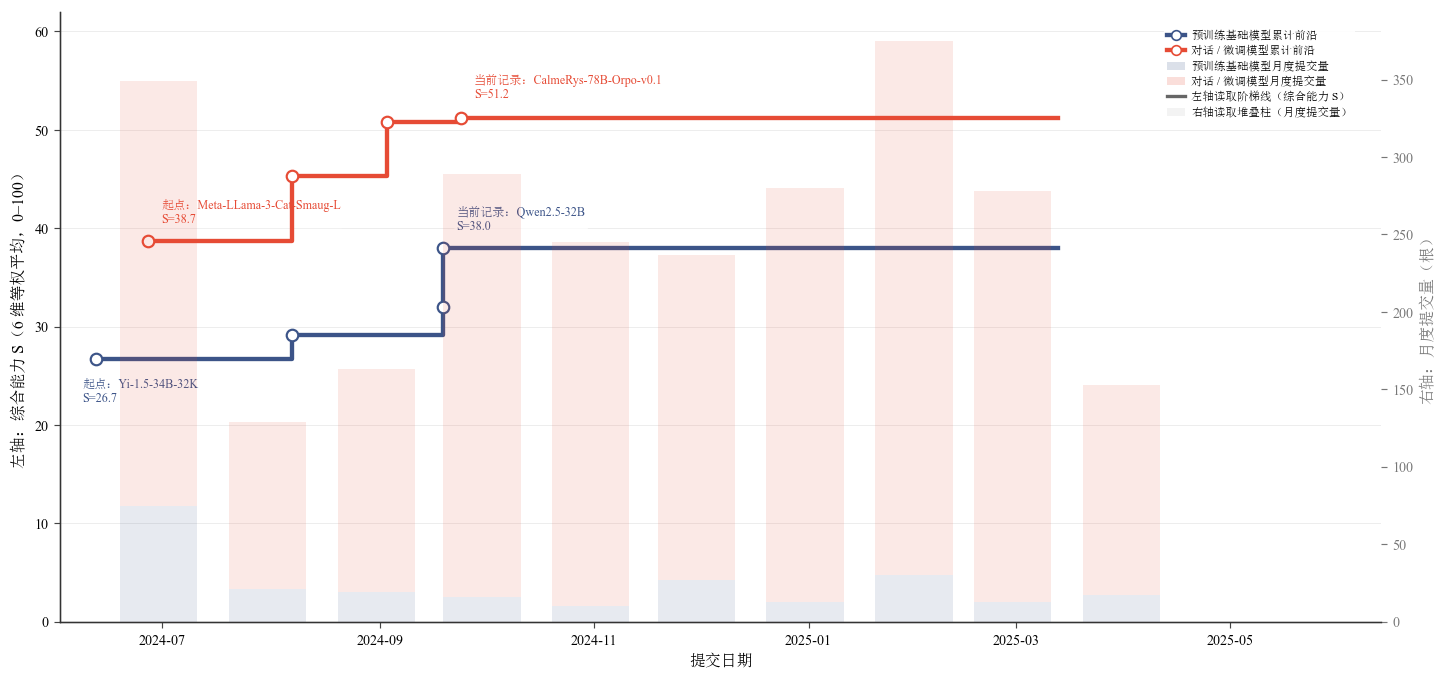

MERG NOT subset; don't know how to subset; dropped


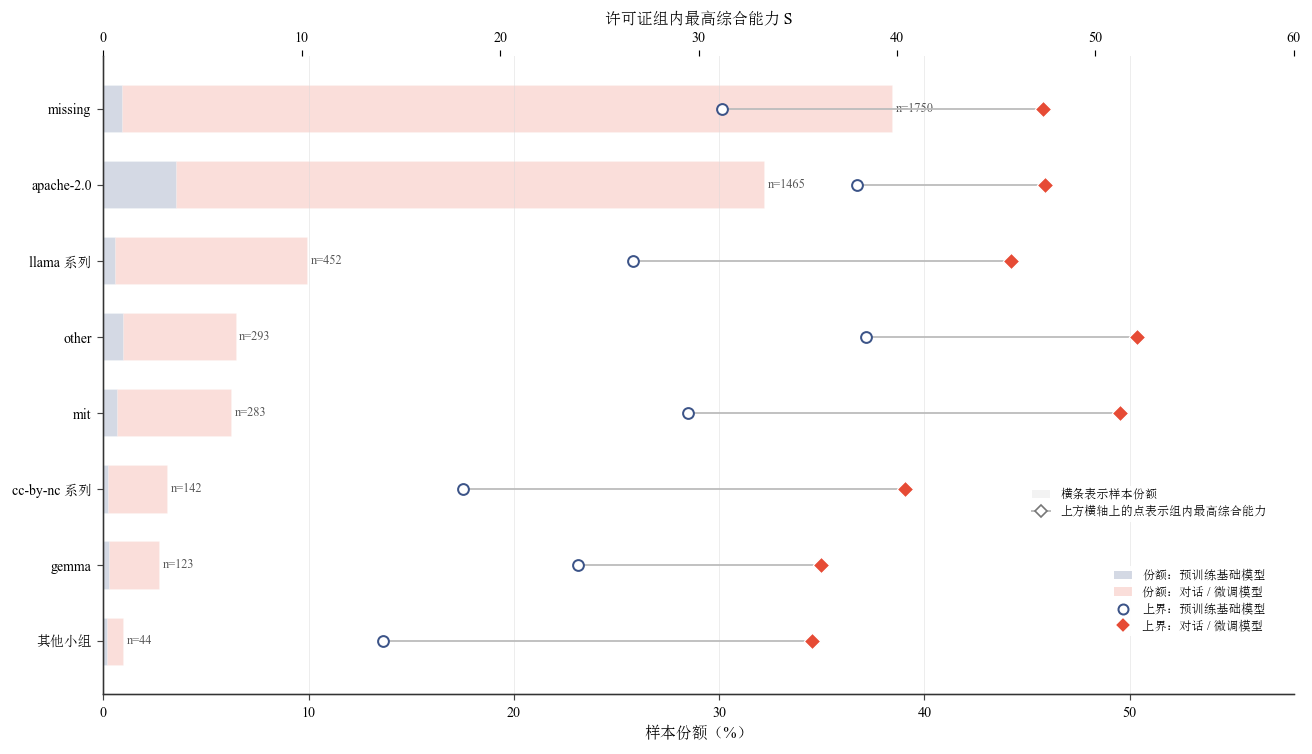

In [20]:
# ============ 1. 读取附件 C、建立分析表 ============
C1 = pd.read_csv(CDIR / 'leaderboard_cleaned.csv'); C2 = pd.read_csv(CDIR / 'leaderboard_enhanced.csv'); C3 = pd.read_csv(CDIR / 'leaderboard_extended_timeseries.csv')
C4 = pd.read_csv(CDIR / 'epoch_all_ai_models.csv'); C6 = pd.read_csv(CDIR / 'loss_benchmark_bridge_expanded.csv'); C5 = pd.read_csv(CDIR / 'loss_benchmark_bridge.csv'); C7 = pd.read_csv(CDIR / 'model_architecture_metadata.csv')
C8W = pd.read_csv(lzma.open(C8DIR / 'c8_task_scores_wide.csv.xz')); C8M = pd.read_csv(C8DIR / 'c8_meta.csv'); C8CFG = json.load(open(C8DIR / 'c8_task_config.json', encoding='utf-8'))
DIMS = ['IFEval', 'BBH', 'MATH Lvl 5', 'GPQA', 'MUSR', 'MMLU-PRO']
LB = C1.rename(columns={'Average ⬆️': 'S', '#Params (B)': 'N_B', 'Submission Date': 'date_sub', 'Hub License': 'license', 'Type': 'type_raw'}).copy()
LB['date_sub'] = pd.to_datetime(LB['date_sub'], errors='coerce'); LB['tau'] = tau(LB['date_sub'])
def type_group(t):
    t = str(t)
    if 'pretrained' in t: return 'pretrained'
    if any(k in t for k in ('chat', 'fine-tuned', 'merges')): return 'chat/finetuned'
    return 'other'
LB['type'] = LB['type_raw'].map(type_group)
LIC_OK = {'apache-2.0', 'mit', 'llama2', 'llama3', 'llama3.1', 'llama3.2', 'llama3.3', 'gemma', 'cc-by-4.0', 'cc-by-sa-4.0', 'cc-by-nc-4.0', 'cc-by-nc-sa-4.0', 'cc-by-nc-nd-4.0', 'bigscience-bloom-rail-1.0', 'bigscience-openrail-m', 'creativeml-openrail-m', 'openrail', 'gpl-3.0', 'agpl-3.0', 'lgpl-3.0', 'bsd-3-clause', 'bsd-2-clause', 'cc0-1.0', 'artistic-2.0', 'mpl-2.0', 'openrail++', 'llama-2', 'wtfpl', 'unlicense', 'deepseek', 'yi-license'}
LB['lic'] = LB['license'].fillna('missing').str.lower().str.strip()
LB['open_strict'] = LB['lic'].isin(LIC_OK); LB['open_broad'] = True
LB = LB.merge(C2[['Model', 'Epoch_AI_Publication_Date', 'Epoch_AI_Open_Weights', 'Epoch_AI_Organization']].drop_duplicates('Model'), on='Model', how='left')
LB['date_pub'] = pd.to_datetime(LB['Epoch_AI_Publication_Date'], errors='coerce')
C8M['Model'] = C8M['model_name']; C8M['date_eval'] = pd.to_datetime(C8M['date_unix'], unit='s', errors='coerce')
LB = LB.merge(C8M[['Model', 'model_dir', 'date_eval', 'model_num_parameters']].drop_duplicates('Model'), on='Model', how='left')
valid = (LB['N_B'] > 0) & LB['date_sub'].notna() & LB['S'].notna() & (LB['type'] != 'other')
print('C1 原始 %d 行；有效（参数量>0、有提交日期、类型可比）%d 行；剔除 %d 行' % (len(LB), valid.sum(), (~valid).sum()))
LB = LB[valid].copy(); LB['lnN'] = np.log(LB['N_B'] * 1e9); LB['y'] = logit(np.clip(LB['S'] / 100, 1e-3, 1 - 1e-3))
# 口径统计
tab = pd.DataFrame({'全部': LB.groupby('type').size(), '宽口径（权重开源）': LB[LB.open_broad].groupby('type').size(), '严口径（许可证允许研究与复现）': LB[LB.open_strict].groupby('type').size()})
tab.loc['合计'] = tab.sum(); print('\n模型数（按类型 x 口径）:'); display(tab)
lic_tab = LB.groupby('lic').agg(n=('Model', 'size'), 严口径=('open_strict', 'first'), 最高分=('S', 'max')).sort_values('n', ascending=False); print('许可证分布（前 15）:'); display(lic_tab.head(15))
m_ = LB['Epoch_AI_Open_Weights'].notna(); print('与 Epoch AI 开源权重字段交叉核对: 匹配 %d 个模型，其中 Open_Weights=Yes %d, No %d；严口径与 Epoch=Yes 的一致率 %.1f%%' % (m_.sum(), (LB.loc[m_, 'Epoch_AI_Open_Weights'] == 'Yes').sum(), (LB.loc[m_, 'Epoch_AI_Open_Weights'] == 'No').sum(), 100 * (LB.loc[m_ & (LB['Epoch_AI_Open_Weights'] == 'Yes'), 'open_strict']).mean()))
# 时间轴口径：三个时间的滞后
lag_pub = (LB['date_sub'] - LB['date_pub']).dt.days; lag_eval = (LB['date_eval'] - LB['date_sub']).dt.days
LB['lag_pub_submit_month'] = lag_pub / 30.4375
print('时间轴口径: 提交日期 - Epoch 发布日期（%d 个可比模型）: 中位 %.0f 天, 四分位 [%.0f, %.0f]；C8 评测时间 - 提交日期（%d 个）: 中位 %.0f 天' % (lag_pub.notna().sum(), lag_pub.median(), lag_pub.quantile(.25), lag_pub.quantile(.75), lag_eval.notna().sum(), lag_eval.median()))
LB.to_csv(TAB / 'leaderboard_analysis_table.csv', index=False, encoding='utf-8-sig'); tab.to_csv(TAB / 'open_source_criteria_counts.csv', encoding='utf-8-sig')

# 记录包络（前沿）：按类型、严口径，累计最大值及其保持者
def envelope(df, init_end='2024-06-30'):
    """记录包络：首月（排行榜 v2 上线时集中提交的历史模型）视为初始批次，取其最高者为起点；之后逐条刷新记录"""
    d = df.sort_values(['date_sub', 'S']).reset_index(drop=True); init = d[d['date_sub'] <= init_end]; r0 = init.loc[init['S'].idxmax()]
    rows = [{'date': r0['date_sub'], 'tau': r0['tau'], 'S': r0['S'], 'Model': r0['Model'], 'N_B': r0['N_B'], 'type': r0['type'], 'init_batch': True}]; best = r0['S']
    for _, r in d[d['date_sub'] > init_end].iterrows():
        if r['S'] > best: best = r['S']; rows.append({'date': r['date_sub'], 'tau': r['tau'], 'S': r['S'], 'Model': r['Model'], 'N_B': r['N_B'], 'type': r['type'], 'init_batch': False})
    return pd.DataFrame(rows)
ENV = {g: envelope(LB[(LB['type'] == g) & LB['open_strict']]) for g in ('pretrained', 'chat/finetuned')}
for g, e in ENV.items(): print('\n%s 前沿记录（严口径；首行 = 首月初始批次的最高者）:' % g); display(e[['date', 'Model', 'N_B', 'S']])

# ---- 图 1（论证导向）：能力前沿记录 + 月度提交活跃度（单图双纵轴） ----
d_ = LB[LB.open_strict].copy(); d_['month'] = d_['date_sub'].dt.to_period('M')
mon = d_.groupby(['month', 'type']).size().unstack(fill_value=0).sort_index(); mx = mon.index.to_timestamp() + pd.offsets.MonthEnd(0)
fig, ax = plt.subplots(figsize=(14.2, 6.6)); axv = ax.twinx(); fig.subplots_adjust(top=.88)
bottom = np.zeros(len(mon), float); bar_handles = []
for g, c in COL_TYPE.items():
    vals = mon[g].values if g in mon.columns else np.zeros(len(mon))
    axv.bar(mx, vals, bottom=bottom, width=22, color=c, alpha=.12, edgecolor='none', zorder=0)
    bottom += vals
    bar_handles.append(Patch(facecolor=c, alpha=.18, label=NAME_TYPE[g] + '月度提交量'))
axv.set_ylabel('右轴：月度提交量（根）', color='#777777')
axv.tick_params(axis='y', colors='#777777')
axv.spines['top'].set_visible(False); axv.spines['right'].set_color('#BBBBBB')
line_handles = []
for g, c in COL_TYPE.items():
    e = ENV[g]; xs = e['date'].tolist() + [d_['date_sub'].max()]; ys = e['S'].tolist() + [e['S'].iloc[-1]]
    ax.step(xs, ys, where='post', color=c, lw=2.6, zorder=4)
    ax.scatter(e['date'], e['S'], s=48, facecolor='white', edgecolor=c, lw=1.3, zorder=5)
    line_handles.append(Line2D([0], [0], color=c, lw=2.6, marker='o', mfc='white', mec=c, ms=5.8, label=NAME_TYPE[g] + '累计前沿'))
    lab_rows = [e.iloc[0], e.iloc[-1]] if len(e) >= 2 else [e.iloc[0]]
    offs = [(-8, -12), (8, 9)] if g == 'pretrained' else [(8, 9), (8, 10)]
    for rr, (dx, dy) in zip(lab_rows, offs):
        tag = '起点' if rr.equals(e.iloc[0]) else '当前记录'
        ax.annotate(f"{tag}：{str(rr['Model']).split('/')[-1][:24]}\nS={rr['S']:.1f}", (rr['date'], rr['S']), xytext=(dx, dy), textcoords='offset points', fontsize=7.3, color=c,
                    ha='left', va='bottom' if dy >= 0 else 'top', bbox=dict(boxstyle='round,pad=.18', facecolor='white', edgecolor='none', alpha=.75))
ax.set_ylim(0, 62)
x_left = d_['date_sub'].min() - pd.Timedelta(days=6); x_right = d_['date_sub'].max() + pd.Timedelta(days=92)
ax.set_xlim(x_left, x_right); axv.set_xlim(x_left, x_right)
ax.set_ylabel('左轴：综合能力 S（6 维等权平均，0–100）'); ax.set_xlabel('提交日期')
ax.xaxis.set_major_locator(mpl.dates.MonthLocator(interval=2)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m'))
nature_ax(ax, 'y')
info_handles = [Line2D([0], [0], color='#666666', lw=2.0, label='左轴读取阶梯线（综合能力 S）'),
                Patch(facecolor='#BDBDBD', alpha=.18, edgecolor='none', label='右轴读取堆叠柱（月度提交量）')]
ax.legend(handles=line_handles + bar_handles + info_handles, loc='upper right', bbox_to_anchor=(.985, .985),
          frameon=True, facecolor='white', edgecolor='none', framealpha=.90, ncol=1,
          fontsize=6.9, borderpad=.28, labelspacing=.36, handlelength=1.55, handletextpad=.55)
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig01_frontier_activity_argument_v8b.png'); plt.show()

# ---- 图 2（论证导向）：许可证结构与能力上界（单图双横轴） ----
lic_grp = LB['lic'].map(lambda s: s if s in ('apache-2.0', 'mit', 'other', 'missing') else ('llama 系列' if str(s).startswith('llama') else ('gemma' if s == 'gemma' else ('cc-by-nc 系列' if 'nc' in str(s) else ('cc-by 系列' if str(s).startswith('cc-by') else '其他白名单' if s in LIC_OK else '其他/不明')))))
LB['lic_grp'] = lic_grp
lic_count = LB.groupby('lic_grp').size().sort_values(ascending=False)
small_mask = lic_count / lic_count.sum() < 0.015
keep_grp = lic_count[~small_mask].index.tolist()
LB['lic_plot'] = np.where(LB['lic_grp'].isin(keep_grp), LB['lic_grp'], '其他小组')
lic_plot = LB.groupby('lic_plot').size().sort_values(ascending=False)
share_type = LB.groupby(['lic_plot', 'type']).size().unstack(fill_value=0).reindex(lic_plot.index).reindex(columns=['pretrained', 'chat/finetuned'], fill_value=0)
share_pct = share_type.div(share_type.sum().sum()).mul(100)
frontier_lic = LB.groupby(['lic_plot', 'type'])['S'].max().unstack().reindex(lic_plot.index)
y = np.arange(len(lic_plot))
fig, ax = plt.subplots(figsize=(12.8, 6.9))
left = np.zeros(len(lic_plot), float)
for g, c in [('pretrained', C_NAVY), ('chat/finetuned', C_CORAL)]:
    vals = share_pct[g].values
    ax.barh(y, vals, left=left, height=.62, color=c, alpha=.22 if g == 'pretrained' else .18, edgecolor='white', linewidth=.7)
    left += vals
for i, n in enumerate(lic_plot.values):
    ax.text(left[i] + .18, i, f'n={int(n)}', va='center', ha='left', fontsize=7.4, color='#555555')
ax.set_yticks(y); ax.set_yticklabels(lic_plot.index, fontsize=8.3); ax.invert_yaxis()
ax.set_xlim(0, max(58, float(np.nanmax(left)) + 18))
ax.set_xlabel('样本份额（%）'); nature_ax(ax, 'x')
ax2 = ax.twiny(); ax2.set_xlim(0, max(60, np.nanmax(frontier_lic.values) + 4)); ax2.set_xlabel('许可证组内最高综合能力 S')
for i, lab in enumerate(lic_plot.index):
    p = frontier_lic.loc[lab, 'pretrained'] if 'pretrained' in frontier_lic.columns else np.nan
    c = frontier_lic.loc[lab, 'chat/finetuned'] if 'chat/finetuned' in frontier_lic.columns else np.nan
    if np.isfinite(p) and np.isfinite(c): ax2.plot([p, c], [i, i], color='#BDBDBD', lw=1.1, zorder=3)
    if np.isfinite(p): ax2.scatter(p, i, s=42, marker='o', facecolor='white', edgecolor=C_NAVY, lw=1.2, zorder=4)
    if np.isfinite(c): ax2.scatter(c, i, s=48, marker='D', facecolor=C_CORAL, edgecolor='white', lw=.7, zorder=5)
share_handles = [Patch(facecolor=C_NAVY, alpha=.22, label='份额：预训练基础模型'), Patch(facecolor=C_CORAL, alpha=.18, label='份额：对话 / 微调模型')]
front_handles = [Line2D([0], [0], marker='o', color='none', mfc='white', mec=C_NAVY, mew=1.2, ms=6, label='上界：预训练基础模型'),
                 Line2D([0], [0], marker='D', color='none', mfc=C_CORAL, mec='white', ms=6.5, label='上界：对话 / 微调模型')]
info_handles = [Patch(facecolor='#BDBDBD', alpha=.18, edgecolor='none', label='横条表示样本份额'),
                Line2D([0], [0], color='#BDBDBD', lw=1.2, marker='D', mfc='white', mec='#777777', ms=5.5, label='上方横轴上的点表示组内最高综合能力')]
leg1 = ax.legend(handles=share_handles + front_handles, frameon=True, facecolor='white', edgecolor='none', framealpha=.92,
                 fontsize=7.4, loc='lower right', bbox_to_anchor=(.985, .08), borderpad=.30, labelspacing=.38, handlelength=1.5)
ax.add_artist(leg1)
ax.legend(handles=info_handles, frameon=True, facecolor='white', edgecolor='none', framealpha=.92,
          fontsize=7.3, loc='lower right', bbox_to_anchor=(.985, .26), borderpad=.30, labelspacing=.38, handlelength=1.5)
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig02_license_structure_frontier_v8b.png'); plt.show()






## 2. C8 逐任务聚合与任务稳定性

### 2.1 综合能力一致性
对 39 个叶子任务按经验随机基线归一，再按有效样本量聚合到 6 个 benchmark 家族，并六族等权得到 $S^{C8}$。该指标用于独立核对 C1 `Average`，避免把综合分结论建立在单一汇总字段上。

### 2.2 Task-level Bootstrap Stability
逐任务拟合
$$\operatorname{logit}(\tilde a_{ij})=\beta_{0j}+\beta_j\ln N_i+\gamma_j\tau_i+\delta_j I[chat],$$
并在模型级样本上 Bootstrap，计算
$$P_j^{scale}=P(\beta_j>0),\qquad P_j^{time}=P(\gamma_j>0).$$
只有正向概率达到 0.9 才标记为稳定驱动，否则记为 `mixed/uncertain`。这一分析用于回答“能力进步是否具有任务异质性”。


C8 叶子任务 39 个（BBH 24, GPQA 3, MATH 7, MUSR 3, IFEval 1, MMLU-PRO 1）; 与 C1 匹配 1886 个模型
由子任务重建的综合分 S_C8 与 C1 Average: Pearson 0.9891, Spearman 0.9916
任务级分析表（前 10 行）:


,task,family,n_samples,frontier_early_top5,frontier_late_top5,gain,beta_lnN,gamma_month,driver,label
0,leaderboard_bbh_boolean_expressions,BBH,250.0000,0.8000,0.8648,0.0648,0.9929,0.0635,双驱动,bbh boolean expressions
1,leaderboard_bbh_causal_judgement,BBH,187.0000,0.3700,0.3675,-0.0025,0.4930,0.0145,双驱动,bbh causal judgement
2,leaderboard_bbh_date_understanding,BBH,250.0000,0.5905,0.7000,0.1095,0.7618,0.0528,技术驱动,bbh date understanding
3,leaderboard_bbh_disambiguation_qa,BBH,250.0000,0.6165,0.6307,0.0142,0.8359,-0.0181,mixed/uncertain,bbh disambiguation qa
4,leaderboard_bbh_formal_fallacies,BBH,250.0000,0.4746,0.5435,0.0688,0.5690,0.0514,技术驱动,bbh formal fallacies
5,leaderboard_bbh_geometric_shapes,BBH,250.0000,0.5223,0.5668,0.0445,0.5381,0.0293,技术驱动,bbh geometric shapes
6,leaderboard_bbh_hyperbaton,BBH,250.0000,0.6705,0.6415,-0.0291,0.6411,0.0496,技术驱动,bbh hyperbaton
7,leaderboard_bbh_logical_deduction_five_objects,BBH,250.0000,0.4926,0.5637,0.0711,0.9070,0.0741,双驱动,bbh logical deduction five objects
8,leaderboard_bbh_logical_deduction_seven_objects,BBH,250.0000,0.4931,0.5657,0.0726,0.9022,0.0477,技术驱动,bbh logical deduction seven objects
9,leaderboard_bbh_logical_deduction_three_objects,BBH,250.0000,0.7778,0.8889,0.1111,1.1165,0.1246,技术驱动,bbh logical deduction three objects


MERG NOT subset; don't know how to subset; dropped


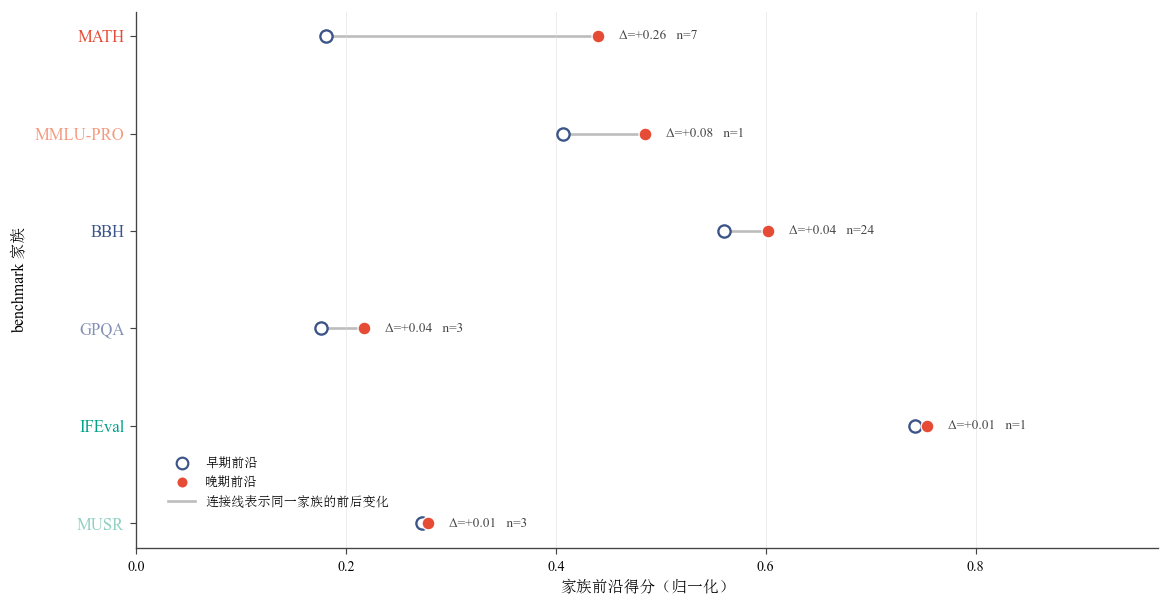

MERG NOT subset; don't know how to subset; dropped


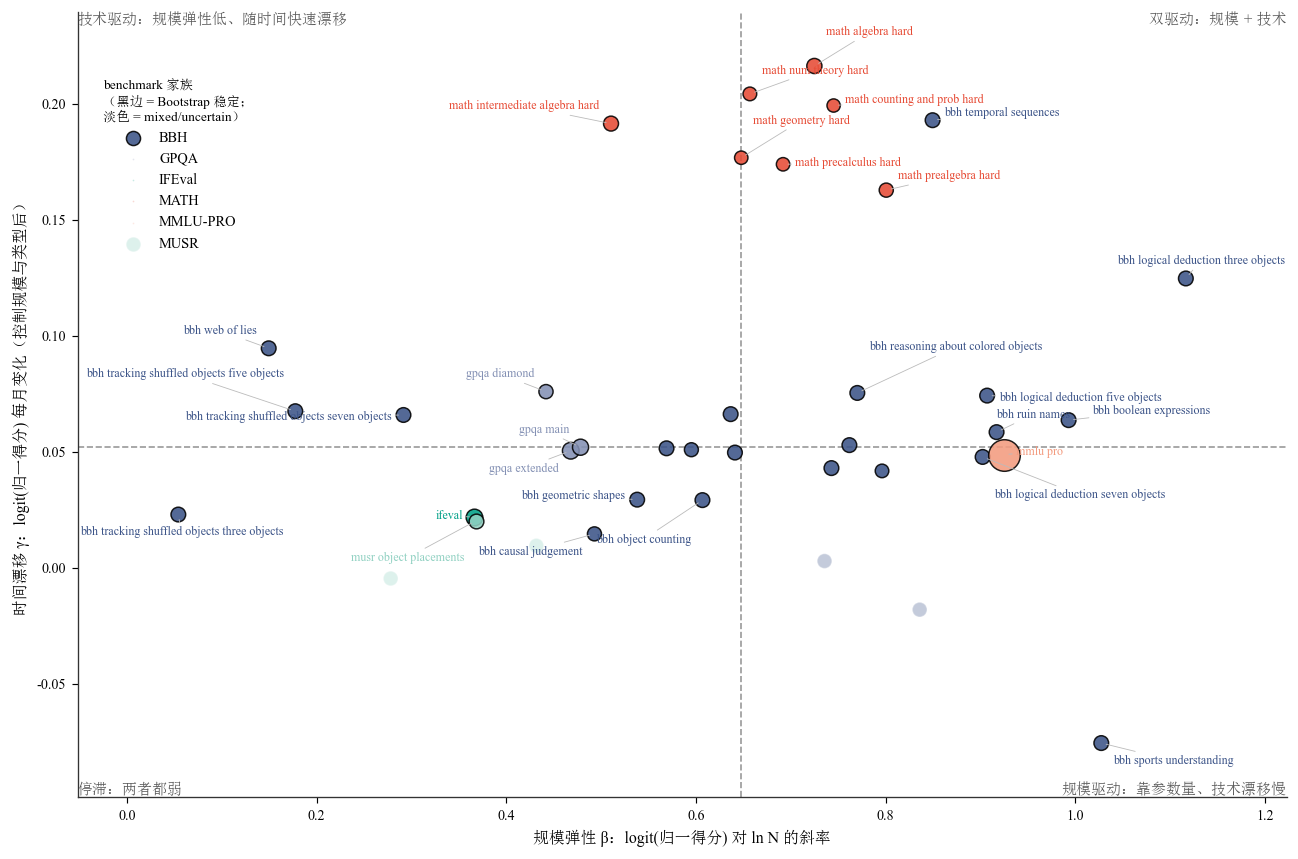

In [21]:
# ============ 2. C8 逐任务聚合分析 ============
tasks_all = sorted(set(c.split('|')[0] for c in C8W.columns if '|' in c))
def family_of(t):
    if t.startswith('leaderboard_bbh'): return 'BBH'
    if t.startswith('leaderboard_gpqa'): return 'GPQA'
    if t.startswith('leaderboard_math'): return 'MATH'
    if t.startswith('leaderboard_musr'): return 'MUSR'
    if t == 'leaderboard_ifeval': return 'IFEval'
    if t == 'leaderboard_mmlu_pro': return 'MMLU-PRO'
    return 'other'
AGG = {'leaderboard', 'leaderboard_bbh', 'leaderboard_gpqa', 'leaderboard_math_hard', 'leaderboard_musr', 'leaderboard_arc_challenge'}
LEAF = [t for t in tasks_all if t not in AGG and family_of(t) != 'other']
def main_metric(t):
    if t == 'leaderboard_ifeval': return 0.5 * (C8W['%s|prompt_level_strict_acc' % t] + C8W['%s|inst_level_strict_acc' % t])
    if t.startswith('leaderboard_math'): return C8W['%s|exact_match' % t]
    if ('%s|acc_norm' % t) in C8W: return C8W['%s|acc_norm' % t]
    return C8W['%s|acc' % t]
RAW = pd.DataFrame({t: main_metric(t) for t in LEAF}); RAW.index = C8W['model_dir']
NS = {t: float(C8CFG['n_samples'].get(t, {}).get('effective', np.nan)) for t in LEAF}
BASE = RAW.quantile(0.02); NORM = ((RAW - BASE) / (1 - BASE)).clip(0, 1)
FAM = {}
for f in FAM_COLORS:
    cols = [t for t in LEAF if family_of(t) == f]; w = np.array([NS[t] for t in cols]); FAM[f] = (NORM[cols].values * w).sum(axis=1) / w.sum()
FAMDF = pd.DataFrame(FAM, index=NORM.index); FAMDF['S_C8'] = 100 * FAMDF[list(FAM_COLORS)].mean(axis=1)
LB = LB.merge(FAMDF[['S_C8']], left_on='model_dir', right_index=True, how='left')
ok = LB['S_C8'].notna()
print('C8 叶子任务 %d 个（BBH %d, GPQA %d, MATH %d, MUSR %d, IFEval 1, MMLU-PRO 1）; 与 C1 匹配 %d 个模型' % (len(LEAF), sum(family_of(t) == 'BBH' for t in LEAF), sum(family_of(t) == 'GPQA' for t in LEAF), sum(family_of(t) == 'MATH' for t in LEAF), sum(family_of(t) == 'MUSR' for t in LEAF), ok.sum()))
print('由子任务重建的综合分 S_C8 与 C1 Average: Pearson %.4f, Spearman %.4f' % (stats.pearsonr(LB.loc[ok, 'S_C8'], LB.loc[ok, 'S'])[0], stats.spearmanr(LB.loc[ok, 'S_C8'], LB.loc[ok, 'S'])[0]))

# 任务层分析表
rows = []
for task in LEAF:
    fam = family_of(task); sc = NORM[task]
    d = LB[['Model', 'type', 'open_strict', 'S', 'tau', 'lnN', 'model_dir']].merge(sc.rename('score'), left_on='model_dir', right_index=True, how='inner')
    d = d[(d['open_strict']) & d['score'].notna()].copy()
    if len(d) < 20: continue
    q_early, q_late = d['tau'].quantile(.33), d['tau'].quantile(.67)
    frontier_early = d.loc[d['tau'] <= q_early, 'score'].quantile(.95); frontier_late = d.loc[d['tau'] >= q_late, 'score'].quantile(.95)
    gain = frontier_late - frontier_early
    X = np.column_stack([np.ones(len(d)), d['lnN'].values, d['tau'].values, (d['type'] == 'chat/finetuned').astype(float).values])
    b = np.linalg.lstsq(X, logit(np.clip(d['score'], 1e-3, 1 - 1e-3)), rcond=None)[0]
    bb = []
    for _ in range(N_BOOT_TASK):
        ii = RNG.integers(0, len(d), len(d))
        try: bb.append(np.linalg.lstsq(X[ii], logit(np.clip(d['score'].values[ii], 1e-3, 1 - 1e-3)), rcond=None)[0])
        except: pass
    bb = np.asarray(bb)
    beta, gamma = b[1], b[2]
    stable = (len(bb) > 10 and np.sign(np.percentile(bb[:, 1], [10, 90])).prod() >= 0 and np.sign(np.percentile(bb[:, 2], [10, 90])).prod() >= 0)
    driver = 'mixed/uncertain'
    if stable:
        if beta >= np.median(np.abs(bb[:, 1])) and gamma >= np.median(np.abs(bb[:, 2])): driver = '双驱动'
        elif abs(beta) >= abs(gamma) * 20: driver = '规模驱动'
        elif abs(gamma) >= abs(beta) / 20: driver = '技术驱动'
    label = task.replace('leaderboard_', '').replace('_', ' ')
    rows.append({'task': task, 'family': fam, 'n_samples': NS[task], 'frontier_early_top5': frontier_early, 'frontier_late_top5': frontier_late,
                 'gain': gain, 'beta_lnN': beta, 'gamma_month': gamma, 'driver': driver, 'label': label})
TASK = pd.DataFrame(rows)
TASK.to_csv(TAB / 'c8_task_level_analysis.csv', index=False, encoding='utf-8-sig')
print('任务级分析表（前 10 行）:'); display(TASK.head(10))

# ---- 图 3（论证导向）：benchmark 家族前沿提升（连接点图） ----
fam_plot = TASK.groupby('family').agg(前沿早期=('frontier_early_top5', 'mean'), 前沿晚期=('frontier_late_top5', 'mean'), 增益=('gain', 'mean'), 任务数=('task', 'size')).reindex(['BBH', 'GPQA', 'IFEval', 'MATH', 'MMLU-PRO', 'MUSR'])
fam_plot = fam_plot.sort_values('增益', ascending=False)
y = np.arange(len(fam_plot))
fig, ax = plt.subplots(figsize=(10.2, 5.8)); fig.subplots_adjust(right=.96)
for i, (fam, r) in enumerate(fam_plot.iterrows()):
    ax.plot([r['前沿早期'], r['前沿晚期']], [i, i], color='#BDBDBD', lw=1.6, zorder=1)
    ax.scatter(r['前沿早期'], i, s=54, facecolor='white', edgecolor=C_NAVY, lw=1.4, zorder=3)
    ax.scatter(r['前沿晚期'], i, s=60, facecolor=C_CORAL, edgecolor='white', lw=.8, zorder=4)
    ax.text(max(r['前沿早期'], r['前沿晚期']) + .02, i, f"Δ={r['增益']:+.2f}   n={int(r['任务数'])}", va='center', fontsize=8.0, color='#444444')
ax.set_yticks(y); ax.set_yticklabels(fam_plot.index, fontsize=10)
ax.invert_yaxis(); ax.set_xlim(0, max(.95, fam_plot[['前沿早期', '前沿晚期']].to_numpy().max() + .22))
ax.set_xlabel('家族前沿得分（归一化）'); ax.set_ylabel('benchmark 家族'); nature_ax(ax, 'x')
for tick in ax.get_yticklabels(): tick.set_color(FAM_COLORS.get(tick.get_text(), '#333333'))
handles = [Line2D([0], [0], marker='o', color='none', mfc='white', mec=C_NAVY, mew=1.3, ms=7, label='早期前沿'),
           Line2D([0], [0], marker='o', color='none', mfc=C_CORAL, mec='white', ms=7, label='晚期前沿'),
           Line2D([0], [0], color='#BDBDBD', lw=1.6, label='连接线表示同一家族的前后变化')]
ax.legend(handles=handles, frameon=False, loc='lower left', bbox_to_anchor=(0.02, 0.05), fontsize=7.9)
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig03_family_gain_lollipop_v8.png'); plt.show()

# ---- 图 4（论证导向）：C8 任务驱动机制点状图（恢复为原版点状图） ----
fam_order = ['BBH', 'GPQA', 'IFEval', 'MATH', 'MMLU-PRO', 'MUSR']
fig, ax = plt.subplots(figsize=(13.0, 8.5)); bx, gy = TASK['beta_lnN'].median(), TASK['gamma_month'].median()
ax.axvline(bx, color='#999999', lw=1.0, ls='--'); ax.axhline(gy, color='#999999', lw=1.0, ls='--')
for f in fam_order:
    d = TASK[TASK.family == f].copy(); st = d['driver'] != 'mixed/uncertain'
    ax.scatter(d.loc[~st, 'beta_lnN'], d.loc[~st, 'gamma_month'], s=30 + np.sqrt(d.loc[~st, 'n_samples']) * 3,
               color=FAM_COLORS[f], alpha=0.30, edgecolor='white', linewidths=0.8, label=f if f not in ['BBH'] else None, zorder=2)
    ax.scatter(d.loc[st, 'beta_lnN'], d.loc[st, 'gamma_month'], s=30 + np.sqrt(d.loc[st, 'n_samples']) * 3,
               color=FAM_COLORS[f], alpha=0.88, edgecolor='black', linewidths=0.9, label=f if f == 'BBH' else None, zorder=3)
far = (abs(TASK['beta_lnN'] - bx) > 0.16) | (abs(TASK['gamma_month'] - gy) > 0.02)
lab_df = TASK[(far | TASK['family'].isin(['IFEval', 'MMLU-PRO', 'GPQA', 'MUSR'])) & (TASK['driver'] != 'mixed/uncertain')]
ax.margins(x=0.10, y=0.08)
def repel_labels(ax, rows, iters=300):
    fig_ = ax.figure; fig_.canvas.draw(); rend = fig_.canvas.get_renderer(); texts = []
    for _, r in rows.iterrows():
        right = r['beta_lnN'] >= bx; up = r['gamma_month'] >= gy
        texts.append(ax.annotate(r['label'], (r['beta_lnN'], r['gamma_month']), xytext=(7 if right else -7, 7 if up else -7), textcoords='offset points', fontsize=7.2,
                                 color=FAM_COLORS[r['family']], ha='left' if right else 'right', va='bottom' if up else 'top', zorder=4,
                                 arrowprops=dict(arrowstyle='-', color='#BBBBBB', lw=0.5, shrinkA=0, shrinkB=3)))
    px = 72.0 / fig_.dpi; axbb = ax.get_window_extent(rend)
    for _ in range(iters):
        moved = False; bbs = [t.get_window_extent(rend) for t in texts]
        for i in range(len(texts)):
            for j in range(i + 1, len(texts)):
                a, b = bbs[i], bbs[j]
                if a.overlaps(b):
                    ov_y = min(a.y1, b.y1) - max(a.y0, b.y0); ov_x = min(a.x1, b.x1) - max(a.x0, b.x0)
                    if ov_y <= ov_x * 0.6:
                        s = 1 if (a.y0 + a.y1) >= (b.y0 + b.y1) else -1; d = (ov_y / 2 + 1.5) * px
                        texts[i].xyann = (texts[i].xyann[0], texts[i].xyann[1] + s * d); texts[j].xyann = (texts[j].xyann[0], texts[j].xyann[1] - s * d)
                    else:
                        s = 1 if (a.x0 + a.x1) >= (b.x0 + b.x1) else -1; d = (ov_x / 2 + 1.5) * px
                        texts[i].xyann = (texts[i].xyann[0] + s * d, texts[i].xyann[1]); texts[j].xyann = (texts[j].xyann[0] - s * d, texts[j].xyann[1])
                    moved = True; bbs = [t.get_window_extent(rend) for t in texts]
        for t in texts:
            bb = t.get_window_extent(rend); dx = dy = 0
            if bb.x0 < axbb.x0 + 2: dx = (axbb.x0 + 2 - bb.x0) * px
            if bb.x1 > axbb.x1 - 2: dx = (axbb.x1 - 2 - bb.x1) * px
            if bb.y0 < axbb.y0 + 2: dy = (axbb.y0 + 2 - bb.y0) * px
            if bb.y1 > axbb.y1 - 2: dy = (axbb.y1 - 2 - bb.y1) * px
            if dx or dy: t.xyann = (t.xyann[0] + dx, t.xyann[1] + dy); moved = True
        if not moved: break
repel_labels(ax, lab_df)
xl, yl = ax.get_xlim(), ax.get_ylim()
for (x_, y_, txt) in ((xl[1], yl[1], '双驱动：规模 + 技术'), (xl[0], yl[1], '技术驱动：规模弹性低、随时间快速漂移'), (xl[1], yl[0], '规模驱动：靠参数量、技术漂移慢'), (xl[0], yl[0], '停滞：两者都弱')):
    ax.text(x_, y_, txt, ha='right' if x_ == xl[1] else 'left', va='top' if y_ == yl[1] else 'bottom', fontsize=9, color='#555555', style='italic')
ax.set_xlabel('规模弹性 β：logit(归一得分) 对 ln N 的斜率')
ax.set_ylabel('时间漂移 γ：logit(归一得分) 每月变化（控制规模与类型后）')
ax.legend(frameon=True, fontsize=8.6, loc='upper left', bbox_to_anchor=(0.01, 0.93),
          title='benchmark 家族\n（黑边 = Bootstrap 稳定；\n淡色 = mixed/uncertain）', title_fontsize=8.0,
          facecolor='white', framealpha=0.95, edgecolor='none')
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig04_task_driver_pointplot_v8b.png'); plt.show()




## 3. 能力生产函数：训练算力主口径与双时间轴诊断

### 3.1 参数规模前沿诊断
对 C1 严口径、分类型模型拟合 q=0.9 参数规模前沿面
$$Q_{0.9}(y_i)=\beta_0+\beta_1\ln N_i+\beta_2(\ln N_i)^2+\gamma\tau_i.$$
该模型只用于等能力线、参数需求半衰期与参数规模敏感性，不承担“规模贡献”的主结论。

### 3.2 训练算力前沿模型
对 C1 与 C4 唯一名称匹配的模型，以真实训练算力作为规模主变量，拟合：

- **Compute-Q90**：
  $$Q_{0.9}(y)=\beta_0+\beta_C(\ln C-\widetilde{\ln C})+\gamma t^{pub}+\delta I[chat];$$
- **DATF-Q90**：
  $$Q_{0.9}(y)=\beta_0+\beta_C(\ln C-\widetilde{\ln C})+\gamma t^{pub}+\rho d+\delta I[chat].$$

其中 $d=t^{submit}-t^{pub}$。DATF 用于检验提交延迟是否携带系统性信息；$\rho$ 的符号与大小只作统计诊断。

### 3.3 规模—非规模贡献的主定义
主结论使用 Compute-Q90，在 2021–2023 与 2024–2025 两个时期之间对代表性训练算力和技术年代做 Shapley 两因素分解，并以观测 q90 前沿变化作为总变化：
$$\Delta S_{actual}=\Delta S_{compute}+\Delta S_{time}+\Delta S_{unexplained}.$$
最终直接报告三项占实际变化的比例，不进行截断。这里的时间项称为 **非规模时间漂移**，而非纯算法因果贡献。


pretrained（严口径 n=241，corr(lnN, tau)=-0.29）: 前沿分位回归 q=0.9: b1=-1.535 b2=0.0450 gamma=0.0231/月 [95% CI 0.0056, 0.0501]; 参考规模 3B 处 beta_N=0.427 -> 参数需求半衰期 12.8 月, 非规模进步 = 每年参数 x1.91 [1.17, 4.29]; OLS gamma=0.0332
chat/finetuned（严口径 n=2257，corr(lnN, tau)=-0.12）: 前沿分位回归 q=0.9: b1=2.043 b2=-0.0353 gamma=0.0637/月 [95% CI 0.0569, 0.0712]; 参考规模 8B 处 beta_N=0.434 -> 参数需求半衰期 4.7 月, 非规模进步 = 每年参数 x5.81 [4.58, 7.44]; OLS gamma=0.0597

不同参考规模处的半衰期与年等价参数倍数:


,类型,参考规模,beta_N,参数需求半衰期(月),年等价参数倍数
0,pretrained,1B,0.3304,9.9281,2.3113
1,pretrained,8B,0.5176,15.5530,1.7071
2,pretrained,70B,0.7129,21.4203,1.4745
3,chat/finetuned,1B,0.5812,6.3266,3.7238
4,chat/finetuned,8B,0.4346,4.7304,5.8030
5,chat/finetuned,70B,0.2816,3.0654,15.0808



参数规模敏感性：各参数量区间内 Top-5 均分首季 -> 末季变化:


,类型,规模区间,首季 Top-5 均分,末季 Top-5 均分,同规模增益,n 首季/末季
0,pretrained,0.5-3B,11.9263,15.3728,3.4465,5/5
1,pretrained,3-10B,20.9812,21.5427,0.5615,5/5
2,pretrained,10-30B,22.4088,27.8632,5.4544,5/5
3,pretrained,30-200B,26.2353,NaN,NaN,5/0
4,chat/finetuned,0.5-3B,15.1926,23.2494,8.0568,5/5
5,chat/finetuned,3-10B,31.4152,38.5739,7.1587,5/5
6,chat/finetuned,10-30B,33.3967,44.4050,11.0082,5/5
7,chat/finetuned,30-200B,44.3772,47.1062,2.7290,5/5



与 Epoch AI 训练算力唯一匹配的排行榜模型: 83 个（pretrained 60, chat 23）；exact-tail 48 / normalized-unique 35
发布→提交延迟: 中位 4.2 月，IQR [0.9, 11.2] 月；负延迟 1 个（保留并在稳健性中检查）

训练算力前沿模型:


,模型,beta_C,非规模时间漂移/月,rho_lag,q90伪R2,等效算力年倍数_仅作解释
0,Compute-Q90,0.1286,0.0325,NaN,0.4326,20.7512
1,DATF-Q90,0.1431,0.0607,0.0297,0.4599,162.1443


DATF 延迟系数 rho_lag = 0.0297 / 月；其含义仅为“发布—提交延迟包含系统性信息”的统计诊断。

训练算力主口径贡献分解（三项占实际变化的比例不截断，代数和=100%）:


,类型,早期q90前沿,晚期q90前沿,实际变化,训练算力贡献,非规模时间漂移贡献,未解释项,训练算力贡献占实际%,非规模时间漂移占实际%,未解释项占实际%
0,pretrained,13.6700,32.1900,18.5300,4.6500,7.3100,6.5600,25.1200,39.4800,35.4000
1,chat/finetuned,21.9400,31.5600,9.6200,3.5600,4.1600,1.8900,37.0400,43.2900,19.6700


MERG NOT subset; don't know how to subset; dropped


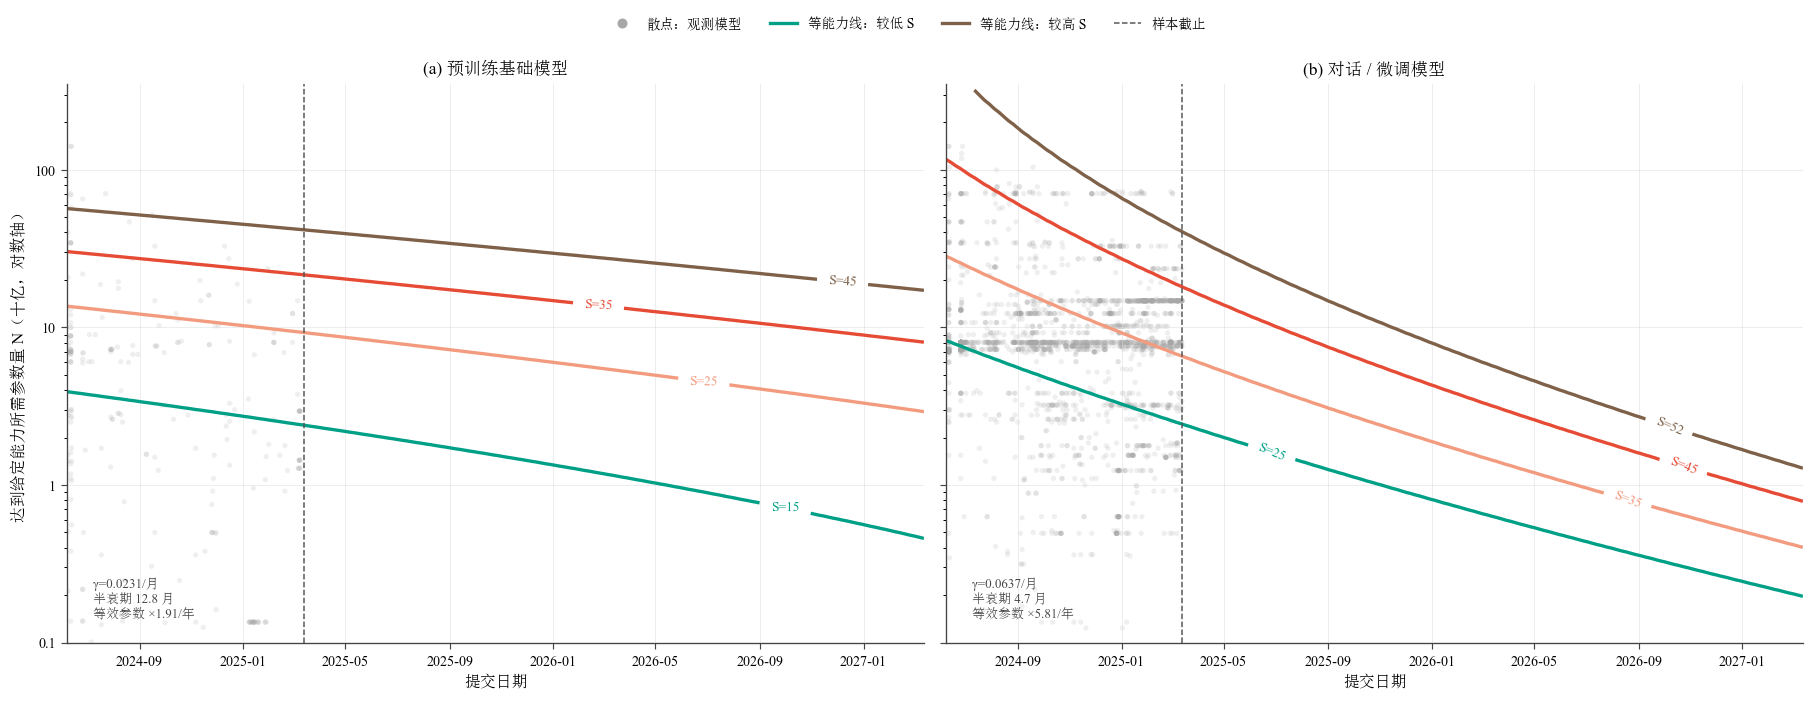

MERG NOT subset; don't know how to subset; dropped


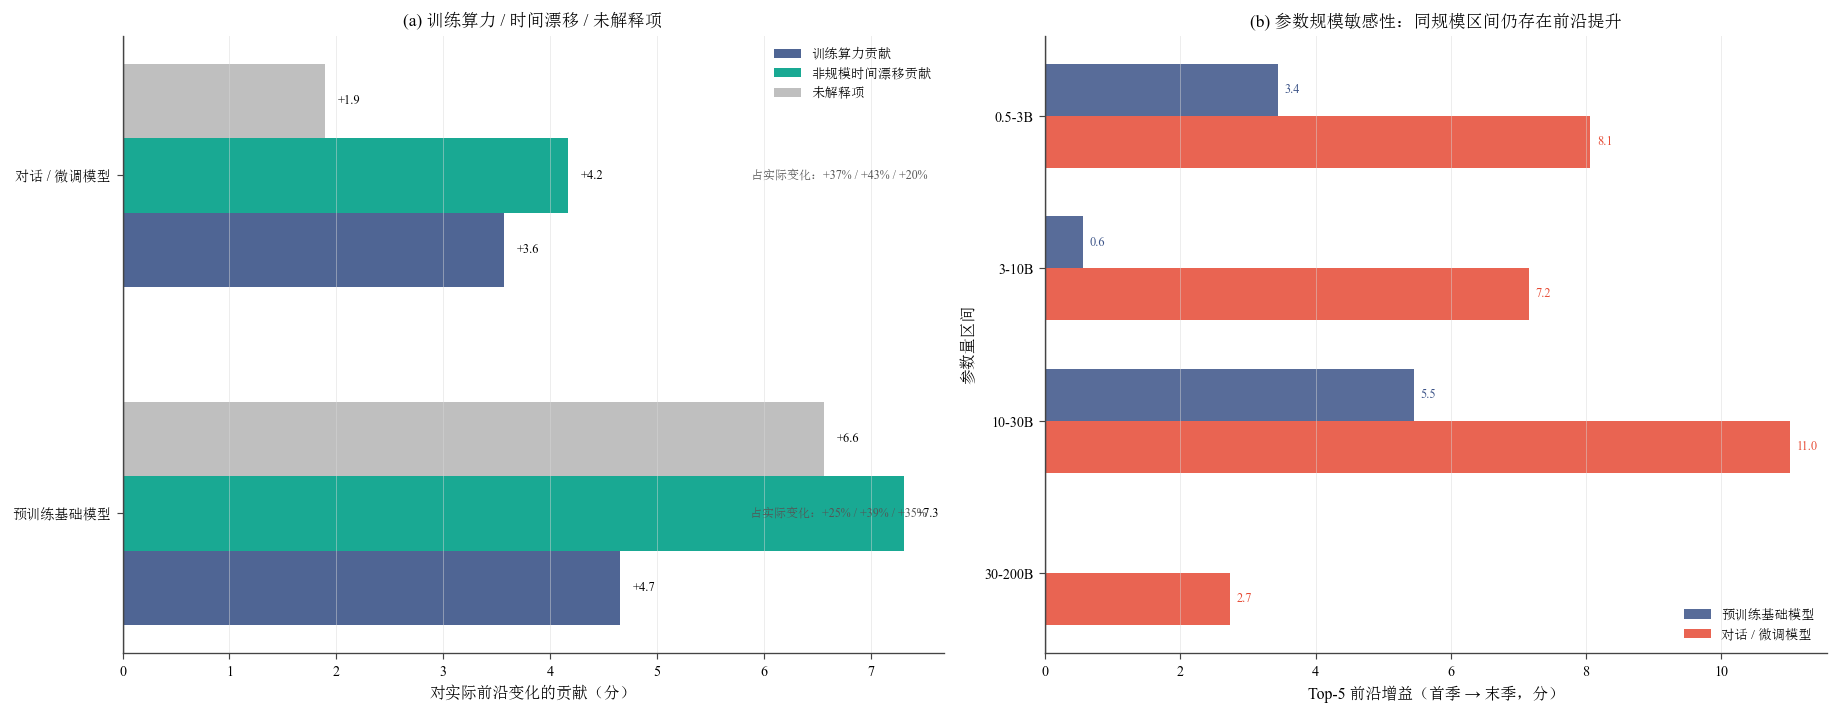

In [22]:
# ============ 3. 能力生产函数、分位数回归与分解 ============
# ============ 稳定版分位数回归 ============
from statsmodels.regression.quantile_regression import QuantReg
import warnings

def quantreg(X, y, q=0.9):
    """
    稳定分位数回归。
    使用 statsmodels QuantReg，避免部分 scipy.linprog 版本在
    大样本 + Bootstrap 下出现 Numerical difficulties。

    返回系数仍然对应原始 X，不改变后续公式与参数含义。
    """
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)

    # 1. 清除异常值
    ok = np.isfinite(y) & np.all(np.isfinite(X), axis=1)
    X = X[ok]
    y = y[ok]

    n, p = X.shape

    if n <= p + 2:
        raise RuntimeError(
            f'分位数回归有效样本过少: n={n}, p={p}'
        )

    # 2. 对除截距以外的变量标准化，改善数值条件
    mu = np.zeros(p)
    sd = np.ones(p)

    active = [0]
    Z_cols = [X[:, 0]]

    for j in range(1, p):
        mu[j] = np.mean(X[:, j])
        sj = np.std(X[:, j])

        # Bootstrap 后某些变量偶尔可能变成常数
        if sj > 1e-10:
            sd[j] = sj
            Z_cols.append((X[:, j] - mu[j]) / sd[j])
            active.append(j)

    Z = np.column_stack(Z_cols)

    # 3. Quantile Regression
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")

        model = QuantReg(y, Z)

        result = model.fit(
            q=q,
            max_iter=5000,
            p_tol=1e-7
        )

    beta_std = np.asarray(result.params, dtype=float)

    if not np.all(np.isfinite(beta_std)):
        raise RuntimeError('分位数回归产生非有限系数')

    # 4. 将标准化后的系数恢复到原变量尺度
    beta = np.zeros(p, dtype=float)

    beta[0] = beta_std[0]

    for k, j in enumerate(active[1:], start=1):
        beta[j] = beta_std[k] / sd[j]
        beta[0] -= beta_std[k] * mu[j] / sd[j]

    return beta
    #r = linprog(c, A_eq=A, b_eq=y, bounds=bounds, method='highs'); return r.x[:p]
def design(lnN, tau_): return np.column_stack([np.ones(len(lnN)), lnN, lnN ** 2, tau_])
def f_pred(b, N, tau_): lnN = np.log(np.asarray(N, float)); return 100 * expit(b[0] + b[1] * lnN + b[2] * lnN ** 2 + b[3] * np.asarray(tau_, float))

Q_FRONT = 0.9; FIT = {}; BOOT = {}
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]; X = design(d['lnN'].values, d['tau'].values); yv = d['y'].values
    b = quantreg(X, yv, Q_FRONT); bo = np.array([quantreg(X[idx], yv[idx], Q_FRONT) for idx in (RNG.integers(0, len(d), len(d)) for _ in range(150))])
    ols, *_ = np.linalg.lstsq(X, yv, rcond=None); FIT[g] = {'b': b, 'ols': ols, 'n': len(d), 'corr_lnN_tau': float(np.corrcoef(d['lnN'], d['tau'])[0, 1])}; BOOT[g] = bo
    Nref = float(np.exp(np.median(d['lnN']))); bN = b[1] + 2 * b[2] * np.log(Nref); bN_bo = bo[:, 1] + 2 * bo[:, 2] * np.log(Nref)
    FIT[g].update({'N_ref': Nref, 'beta_N': bN, 'gamma': b[3], 'half_life_month': np.log(2) * bN / b[3] if b[3] > 0 else np.inf, 'annual_param_multiplier': float(np.exp(12 * b[3] / bN)),
                   'gamma_ci': np.percentile(bo[:, 3], [2.5, 97.5]).tolist(), 'mult_ci': np.percentile(np.exp(12 * bo[:, 3] / bN_bo), [2.5, 97.5]).tolist()})
    print('%s（严口径 n=%d，corr(lnN, tau)=%.2f）: 前沿分位回归 q=%.1f: b1=%.3f b2=%.4f gamma=%.4f/月 [95%% CI %.4f, %.4f]; 参考规模 %.0fB 处 beta_N=%.3f -> 参数需求半衰期 %.1f 月, 非规模进步 = 每年参数 x%.2f [%.2f, %.2f]; OLS gamma=%.4f'
          % (g, len(d), FIT[g]['corr_lnN_tau'], Q_FRONT, b[1], b[2], b[3], *FIT[g]['gamma_ci'], Nref / 1e9, bN, FIT[g]['half_life_month'], FIT[g]['annual_param_multiplier'], *FIT[g]['mult_ci'], ols[3]))

# 参数需求半衰期与年等价参数倍数在不同参考规模处的取值（beta_N 随规模变化）
rows = []
for g in FIT:
    b = FIT[g]['b']
    for Nr in (1e9, 8e9, 70e9):
        bN = b[1] + 2 * b[2] * np.log(Nr); rows.append({'类型': g, '参考规模': '%gB' % (Nr / 1e9), 'beta_N': bN, '参数需求半衰期(月)': np.log(2) * bN / b[3] if b[3] > 0 and bN > 0 else np.inf, '年等价参数倍数': float(np.exp(12 * b[3] / bN)) if bN > 0 else np.nan})
HL = pd.DataFrame(rows); print('\n不同参考规模处的半衰期与年等价参数倍数:'); display(HL); HL.to_csv(TAB / 'half_life_by_scale.csv', index=False, encoding='utf-8-sig')

# ---------- 参数规模敏感性：同规模区间的前沿变化 ----------
BANDS = [(0.5, 3, '0.5-3B'), (3, 10, '3-10B'), (10, 30, '10-30B'), (30, 200, '30-200B')]
rows = []
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB['type'] == g) & LB['open_strict']]
    for lo, hi, lab in BANDS:
        e0 = d[(d['N_B'] >= lo) & (d['N_B'] < hi) & (d['tau'] < 3)]['S'].nlargest(5)
        e1 = d[(d['N_B'] >= lo) & (d['N_B'] < hi) & (d['tau'] >= LB['tau'].max() - 3)]['S'].nlargest(5)
        rows.append({'类型': g, '规模区间': lab, '首季 Top-5 均分': e0.mean(), '末季 Top-5 均分': e1.mean(), '同规模增益': e1.mean() - e0.mean(), 'n 首季/末季': '%d/%d' % (len(e0), len(e1))})
BAND = pd.DataFrame(rows)
print('\n参数规模敏感性：各参数量区间内 Top-5 均分首季 -> 末季变化:'); display(BAND)
BAND.to_csv(TAB / 'same_parameter_scale_gains.csv', index=False, encoding='utf-8-sig')

# ---------- C1 x C4：唯一规范化名称匹配 + 匹配审计 ----------
def norm_name(s):
    s = str(s).lower().split('/')[-1]; s = re.sub(r'[\s_\-\.]', '', s)
    return s.replace('instruct', 'it').replace('chat', '')
C4L = C4[C4['Domain'].astype(str).str.contains('Language')].copy(); C4L['key'] = C4L['Model'].map(norm_name)
C4L['C'] = pd.to_numeric(C4L['Training compute (FLOP)'], errors='coerce'); C4L['date_pub4'] = pd.to_datetime(C4L['Publication date'], errors='coerce')
C4L['D_tokens'] = pd.to_numeric(C4L['Training dataset size (total)'], errors='coerce'); C4L['open_w'] = C4L['Open model weights?']
key_n = C4L.groupby('key').size(); unique_keys = key_n[key_n == 1].index
C4U = C4L[C4L['key'].isin(unique_keys)].dropna(subset=['C']).copy().rename(columns={'Model': 'Model_C4'})
LB['key'] = LB['Model'].map(norm_name)
MC = LB.merge(C4U[['key', 'Model_C4', 'C', 'date_pub4', 'D_tokens', 'open_w', 'Organization']], on='key', how='inner')
MC['match_method'] = np.where(MC['Model'].str.lower().str.split('/').str[-1] == MC['Model_C4'].str.lower().str.split('/').str[-1], 'exact_tail', 'normalized_unique')
MC['tau_pub'] = (MC['date_pub4'] - T0).dt.days / 30.4375; MC['lag_month'] = (MC['date_sub'] - MC['date_pub4']).dt.days / 30.4375
MC = MC.dropna(subset=['tau_pub', 'lag_month', 'C']).copy(); MC['chat'] = (MC['type'] == 'chat/finetuned').astype(float)
LN_C_CENTER = float(np.log(MC['C']).median()); MC['lnC_c'] = np.log(MC['C']) - LN_C_CENTER
print('\n与 Epoch AI 训练算力唯一匹配的排行榜模型: %d 个（pretrained %d, chat %d）；exact-tail %d / normalized-unique %d' % (len(MC), (MC.type == 'pretrained').sum(), (MC.type == 'chat/finetuned').sum(), (MC.match_method == 'exact_tail').sum(), (MC.match_method == 'normalized_unique').sum()))
print('发布→提交延迟: 中位 %.1f 月，IQR [%.1f, %.1f] 月；负延迟 %d 个（保留并在稳健性中检查）' % (MC.lag_month.median(), MC.lag_month.quantile(.25), MC.lag_month.quantile(.75), (MC.lag_month < 0).sum()))

# ---------- Compute-Q90 与 DATF-Q90 ----------
def qloss(resid, q=.9):
    resid = np.asarray(resid, float)
    return float(np.sum(np.where(resid >= 0, q * resid, (q - 1) * resid)))

Xc = np.column_stack([np.ones(len(MC)), MC['lnC_c'], MC['tau_pub'], MC['chat']]); yc = MC['y'].values
bc_q = quantreg(Xc, yc, 0.9)
bo_c_q = np.array([quantreg(Xc[ii], yc[ii], 0.9) for ii in (RNG.integers(0, len(MC), len(MC)) for _ in range(N_BOOT))])
Xd = np.column_stack([np.ones(len(MC)), MC['lnC_c'], MC['tau_pub'], MC['lag_month'], MC['chat']])
bd_q = quantreg(Xd, yc, 0.9)
bo_dual = np.array([quantreg(Xd[ii], yc[ii], 0.9) for ii in (RNG.integers(0, len(MC), len(MC)) for _ in range(N_BOOT))])
null_q = np.quantile(yc, .9); qloss0 = qloss(yc - null_q, .9)
qR2 = 1 - qloss(yc - Xc @ bc_q, .9) / max(qloss0, 1e-12)
qR2_dual = 1 - qloss(yc - Xd @ bd_q, .9) / max(qloss0, 1e-12)

def eq_compute_mult(beta, gamma): return float(np.exp(12 * gamma / beta)) if beta > 0 and np.isfinite(beta) else np.nan
MODEL_C = pd.DataFrame([
    {'模型': 'Compute-Q90', 'beta_C': bc_q[1], '非规模时间漂移/月': bc_q[2], 'rho_lag': np.nan, 'q90伪R2': qR2, '等效算力年倍数_仅作解释': eq_compute_mult(bc_q[1], bc_q[2])},
    {'模型': 'DATF-Q90', 'beta_C': bd_q[1], '非规模时间漂移/月': bd_q[2], 'rho_lag': bd_q[3], 'q90伪R2': qR2_dual, '等效算力年倍数_仅作解释': eq_compute_mult(bd_q[1], bd_q[2])}
])
print('\n训练算力前沿模型:'); display(MODEL_C)
print('DATF 延迟系数 rho_lag = %.4f / 月；其含义仅为“发布—提交延迟包含系统性信息”的统计诊断。' % bd_q[3])
MODEL_C.to_csv(TAB / 'compute_frontier_models.csv', index=False, encoding='utf-8-sig')
MC.to_csv(TAB / 'leaderboard_matched_epoch_compute.csv', index=False, encoding='utf-8-sig')

# ---------- 主贡献分解：训练算力扩张 + 非规模时间漂移 + 未解释项 ----------
def f_compute(b, C, t, chat):
    z = b[0] + b[1] * (np.log(float(C)) - LN_C_CENTER) + b[2] * float(t) + b[3] * float(chat)
    return float(100 * expit(z))

def compute_shapley(b, C0, t0, C1, t1, chat):
    f00 = f_compute(b, C0, t0, chat); f10 = f_compute(b, C1, t0, chat)
    f01 = f_compute(b, C0, t1, chat); f11 = f_compute(b, C1, t1, chat)
    sc = .5 * ((f10 - f00) + (f11 - f01))
    tm = .5 * ((f01 - f00) + (f11 - f10))
    return sc, tm, f00, f11

dec_rows = []
for g, chat_ in [('pretrained', 0.0), ('chat/finetuned', 1.0)]:
    dg = MC[MC['type'] == g].copy()
    d0 = dg[(dg['date_pub4'] >= '2021-01-01') & (dg['date_pub4'] < '2024-01-01')]
    d1 = dg[dg['date_pub4'] >= '2024-01-01']
    if min(len(d0), len(d1)) < 4:
        raise RuntimeError(f'{g} 的 C4 匹配样本不足以做 2021-23 vs 2024-25 训练算力贡献分解')
    C0, C1 = float(np.exp(np.log(d0['C']).median())), float(np.exp(np.log(d1['C']).median()))
    t0, t1 = float(d0['tau_pub'].median()), float(d1['tau_pub'].median())
    S0, S1 = float(d0['S'].quantile(.9)), float(d1['S'].quantile(.9)); actual = S1 - S0
    sc, tm, _, _ = compute_shapley(bc_q, C0, t0, C1, t1, chat_); unexpl = actual - sc - tm
    boot = np.array([compute_shapley(bb, C0, t0, C1, t1, chat_)[:2] for bb in bo_c_q])
    unb = actual - boot[:, 0] - boot[:, 1]
    denom = actual if abs(actual) > 1e-8 else np.nan
    dec_rows.append({
        '类型': g, '时期': '2021-23 → 2024-25', '早期n': len(d0), '晚期n': len(d1),
        '早期q90前沿': S0, '晚期q90前沿': S1, '实际变化': actual,
        '训练算力贡献': sc, '非规模时间漂移贡献': tm, '未解释项': unexpl,
        '训练算力贡献占实际%': 100 * sc / denom, '非规模时间漂移占实际%': 100 * tm / denom, '未解释项占实际%': 100 * unexpl / denom,
        '训练算力贡献95%CI': '[%.2f, %.2f]' % tuple(np.percentile(boot[:, 0], [2.5, 97.5])),
        '时间漂移贡献95%CI': '[%.2f, %.2f]' % tuple(np.percentile(boot[:, 1], [2.5, 97.5])),
        '未解释项95%CI': '[%.2f, %.2f]' % tuple(np.percentile(unb, [2.5, 97.5])),
        'C0': C0, 'C1': C1, 't0': t0, 't1': t1
    })
DECDF = pd.DataFrame(dec_rows)
print('\n训练算力主口径贡献分解（三项占实际变化的比例不截断，代数和=100%）:')
display(DECDF[['类型','早期q90前沿','晚期q90前沿','实际变化','训练算力贡献','非规模时间漂移贡献','未解释项','训练算力贡献占实际%','非规模时间漂移占实际%','未解释项占实际%']].round(2))
DECDF.to_csv(TAB / 'compute_based_contribution_decomposition.csv', index=False, encoding='utf-8-sig')
json.dump({'parameter_frontier': {g: {k: (v.tolist() if isinstance(v, np.ndarray) else v) for k, v in FIT[g].items()} for g in FIT},
           'compute_q90': bc_q.tolist(), 'datf_q90': bd_q.tolist(), 'lnC_center': LN_C_CENTER,
           'contribution': DECDF.to_dict(orient='records')}, open(TAB / 'production_function_fits.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=str)

# ---- 图 5：参数规模等能力线双联图 ----
def _draw_iso_panel(ax, g, panel_lab):
    d = LB[(LB.type == g) & LB.open_strict].copy(); b = FIT[g]['b']
    d0 = d['date_sub'].min(); d1 = LB['date_sub'].max() + pd.DateOffset(months=24)
    dates = pd.date_range(d0, d1, periods=180); tt = np.array([(x - T0).days / 30.4375 for x in dates]); Ngrid = np.geomspace(.12, 320, 150)
    TT, NN = np.meshgrid(tt, Ngrid); Z = f_pred(b, NN * 1e9, TT)
    levels = [15, 25, 35, 45] if g == 'pretrained' else [25, 35, 45, 52]; cols = [C_TEAL, C_GOLD, C_CORAL, C_RUST]
    ax.scatter(d['date_sub'], d['N_B'], s=10, color='#A7A7A7', alpha=.18, edgecolor='none', rasterized=True)
    cs = ax.contour(mpl.dates.date2num(dates), Ngrid, Z, levels=levels, colors=cols, linewidths=2.0)
    ax.clabel(cs, fmt={lv: f'S={lv}' for lv in levels}, inline=True, fontsize=8.0)
    cut = LB.date_sub.max(); ax.axvline(cut, color='#555555', lw=.9, ls='--')
    ax.set_yscale('log'); ax.yaxis.set_major_formatter(plain); ax.set_ylim(.1, 350)
    ax.xaxis_date(); ax.xaxis.set_major_locator(mpl.dates.MonthLocator(interval=4)); ax.xaxis.set_major_formatter(mpl.dates.DateFormatter('%Y-%m'))
    ax.set_xlabel('提交日期'); nature_ax(ax, 'both')
    ax.set_title(f'({panel_lab}) ' + ('预训练基础模型' if g == 'pretrained' else '对话 / 微调模型'), fontsize=10.4)
    ax.text(.03, .04, 'γ=%.4f/月\n半衰期 %.1f 月\n等效参数 ×%.2f/年' % (FIT[g]['gamma'], FIT[g]['half_life_month'], FIT[g]['annual_param_multiplier']), transform=ax.transAxes, fontsize=7.8, color='#444444', va='bottom')
fig, axes = plt.subplots(1, 2, figsize=(15.2, 6.1), sharey=True)
_draw_iso_panel(axes[0], 'pretrained', 'a'); _draw_iso_panel(axes[1], 'chat/finetuned', 'b')
axes[0].set_ylabel('达到给定能力所需参数量 N（十亿，对数轴）')
handles = [Line2D([0], [0], marker='o', color='none', mfc='#A7A7A7', mec='none', ms=6, label='散点：观测模型'), Line2D([0], [0], color=C_TEAL, lw=2, label='等能力线：较低 S'), Line2D([0], [0], color=C_RUST, lw=2, label='等能力线：较高 S'), Line2D([0], [0], color='#555555', lw=.9, ls='--', label='样本截止')]
fig.legend(handles=handles, frameon=False, ncol=4, loc='upper center', bbox_to_anchor=(.5, .96), fontsize=8.2)
fig.suptitle('', y=.995, fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, .93]); savefig('fig05_isoability_dualpanel_v8.png'); plt.show()

# ---- 图 6：训练算力贡献分解 + 参数规模敏感性 ----
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15.4, 6.5), gridspec_kw={'width_ratios': [1.05, 1.0]})
y = np.arange(len(DECDF)); h = .22
vals = [('训练算力贡献', C_NAVY, -h), ('非规模时间漂移贡献', C_TEAL, 0), ('未解释项', '#B8B8B8', h)]
for col, c, off in vals:
    ax1.barh(y + off, DECDF[col], height=h, color=c, alpha=.9, label=col)
    for i, v in enumerate(DECDF[col]): ax1.text(v + (.12 if v >= 0 else -.12), i + off, f'{v:+.1f}', va='center', ha='left' if v >= 0 else 'right', fontsize=7.5)
ax1.axvline(0, color='#444444', lw=.8); ax1.set_yticks(y); ax1.set_yticklabels([NAME_TYPE.get(x, x) for x in DECDF['类型']]); ax1.set_xlabel('对实际前沿变化的贡献（分）'); nature_ax(ax1, 'x'); ax1.legend(frameon=False, fontsize=8)
ax1.set_title('(a) 训练算力 / 时间漂移 / 未解释项', fontsize=10.4)
for i, r in DECDF.iterrows():
    ax1.text(.98, i, '占实际变化：%+.0f%% / %+.0f%% / %+.0f%%' % (r['训练算力贡献占实际%'], r['非规模时间漂移占实际%'], r['未解释项占实际%']), transform=ax1.get_yaxis_transform(), ha='right', va='center', fontsize=7.2, color='#555555')
order_band = [b_[2] for b_ in BANDS]; pre = BAND[BAND.类型 == 'pretrained'].set_index('规模区间').reindex(order_band); chat = BAND[BAND.类型 == 'chat/finetuned'].set_index('规模区间').reindex(order_band)
y2 = np.arange(len(order_band)); hh = .34
ax2.barh(y2 - hh/2, pre['同规模增益'].values, height=hh, color=C_NAVY, alpha=.86, label='预训练基础模型')
ax2.barh(y2 + hh/2, chat['同规模增益'].values, height=hh, color=C_CORAL, alpha=.86, label='对话 / 微调模型')
for i, v in enumerate(pre['同规模增益'].values):
    if np.isfinite(v): ax2.text(v + .10, i - hh/2, f'{v:.1f}', va='center', fontsize=7.4, color=C_NAVY)
for i, v in enumerate(chat['同规模增益'].values):
    if np.isfinite(v): ax2.text(v + .10, i + hh/2, f'{v:.1f}', va='center', fontsize=7.4, color=C_CORAL)
ax2.axvline(0, color='#444444', lw=.8); ax2.set_yticks(y2); ax2.set_yticklabels(order_band); ax2.invert_yaxis(); ax2.set_xlabel('Top-5 前沿增益（首季 → 末季，分）'); ax2.set_ylabel('参数量区间'); nature_ax(ax2, 'x'); ax2.legend(frameon=False, loc='lower right', fontsize=8)
ax2.set_title('(b) 参数规模敏感性：同规模区间仍存在前沿提升', fontsize=10.4)
fig.suptitle('', y=.995, fontsize=11.5)
fig.tight_layout(rect=[0, 0, 1, .95]); savefig('fig06_compute_contribution_dualpanel_v8.png'); plt.show()


## 4. 长周期视角与数据驱动算力增长情景

在 C4 开源语言模型中，以 q=0.9 pinball loss 搜索训练算力增长的最优变化点 $t_c$：
$$t_c^*=\arg\min_{t_c}\left[\sum_{t<t_c}\rho_{0.9}(e_t)+\sum_{t\ge t_c}\rho_{0.9}(e_t)\right],$$
并要求两段都有足够样本。变化点之后的 q90 年增长倍数定义“延续”情景，其对数增长率减半定义“放缓”，$G_{phys}=1$ 定义“停滞”。

变化点及增长率均作为统计估计量报告置信区间；若后段区间跨过 1，则只表述为“点估计显示增长放缓，但不确定性较大”，不把情景参数写成确定事实。

C3 的 2019–2025 长周期数据只用于时代性证据，不与 C1 混为同精度回归样本。


C3 各年最高分与累计记录（仅开源权重模型；GPT-3 与 Chinchilla 为闭源，剔除）:


,Model,Params_B,S3,累计记录
Year,,,,
2019,GPT-2 (1.5B),1.5000,5.0000,5.0000
2021,GPT-J (6B),6.0000,5.0000,5.0000
2022,OPT (175B),175.0000,30.0000,30.0000
2023,LLaMA (65B),65.0000,35.0000,35.0000
2024,MaziyarPanahi/calme-3.2-instruct-78b,77.9650,52.0800,52.0800
2025,fluently-lm/FluentlyLM-Prinum,32.7640,47.2200,52.0800


MERG NOT subset; don't know how to subset; dropped


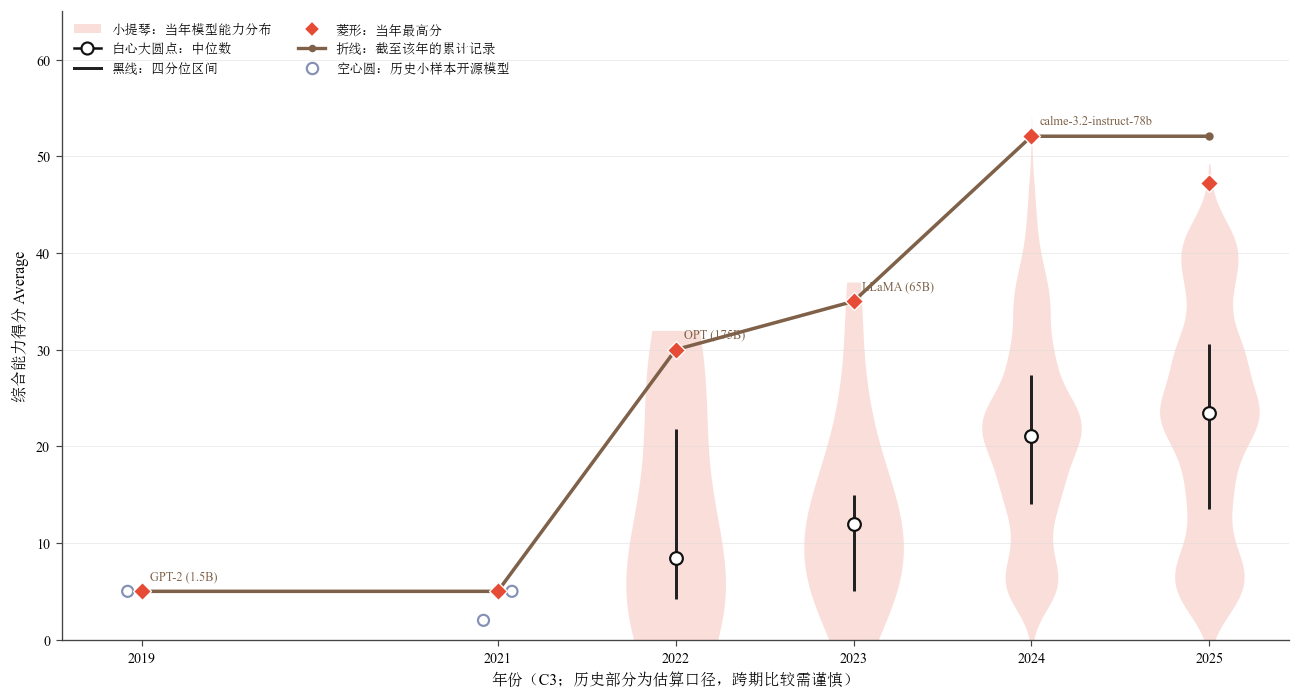

数据驱动 q90 算力增长变化点 = 2024.50 年（前段 n=311，后段 n=184）
变化点前: n=311, q90 前沿算力年增 x3.01 [2.39, 3.59]
变化点后: n=184, q90 前沿算力年增 x1.47 [0.56, 2.28]
算力增长情景 G_phys: {'延续（数据驱动最近段）': 1.47, '放缓（对数增长率减半）': 1.21, '停滞（前沿算力不增长）': 1.0}
变化点后增长率 95% CI = [0.56, 2.28]，情景参数用于外推而非确定事实。
数据截止 2025-03-13 前开源 LM 最大训练算力 3.80e+25；桥接锚点算力 7.80e+24；截止后 C4 新开源 LM 94 个（只作事后核对）


MERG NOT subset; don't know how to subset; dropped


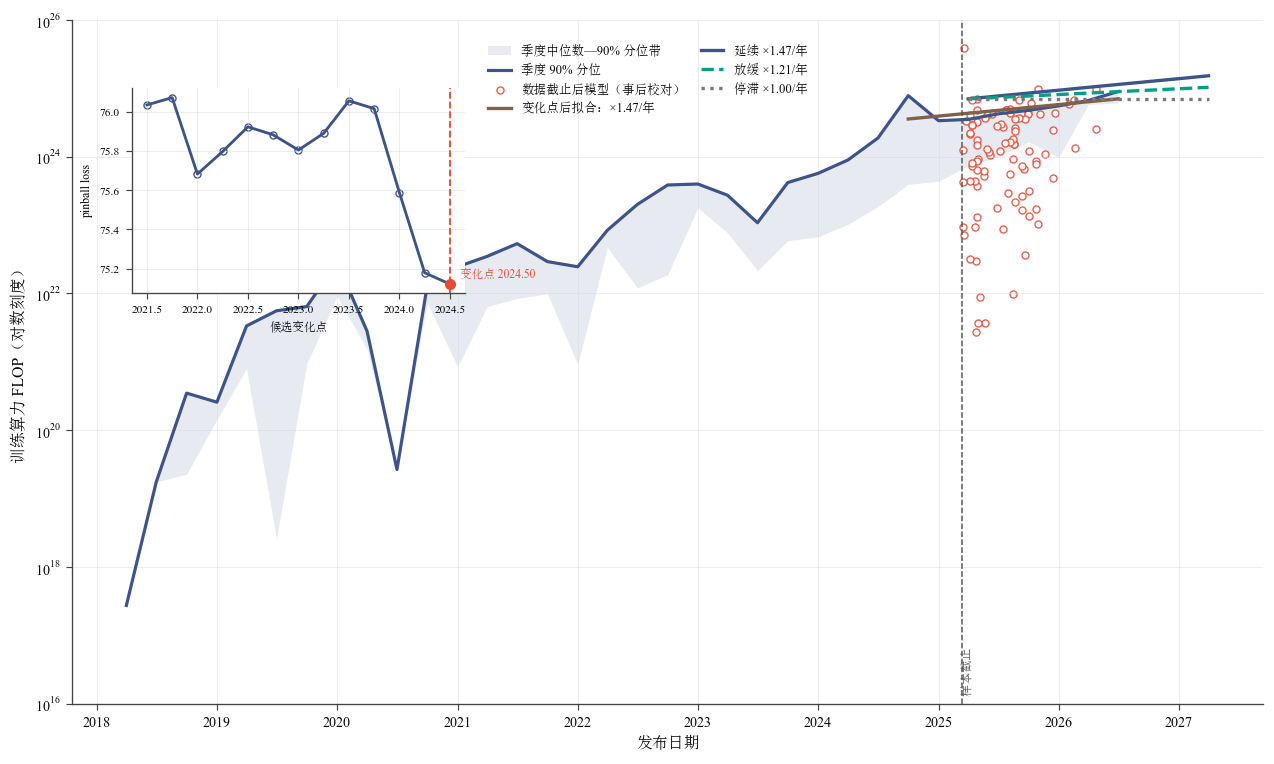

In [23]:
# ============ 4. 长周期视角 + 算力增长情景 ============
C3['is_hist'] = C3['Source'].str.startswith('Historical'); C3['S3'] = C3['Average']
CLOSED_HIST = ('GPT-3', 'Chinchilla')                                   # 历史模型中未开源权重者（不计入开源前沿）
C3['is_open'] = ~(C3['is_hist'] & C3['Model'].str.startswith(CLOSED_HIST))
C3o = C3[C3['is_open']]; yr_max = C3o.groupby('Year').apply(lambda d: d.loc[d['S3'].idxmax()])[['Model', 'Params_B', 'S3']]; yr_front = yr_max.copy(); yr_front['S3'] = yr_max['S3'].cummax()
for y_ in yr_front.index:
    hold = yr_max[yr_max['S3'] == yr_front.loc[y_, 'S3']].index.min(); yr_front.loc[y_, ['Model', 'Params_B']] = yr_max.loc[hold, ['Model', 'Params_B']]
print('C3 各年最高分与累计记录（仅开源权重模型；GPT-3 与 Chinchilla 为闭源，剔除）:'); display(yr_max.join(yr_front[['S3']].rename(columns={'S3': '累计记录'})))
# ---- 图 7（论证导向）：年度能力分布 + 年度最高分 + 累计记录 ----
plot3 = C3[C3['is_open']].copy(); years = sorted(plot3['Year'].dropna().astype(int).unique())
fig, ax = plt.subplots(figsize=(13.2, 6.8))
for y0 in years:
    vals = plot3.loc[plot3['Year'].astype(int) == y0, 'S3'].dropna().values.astype(float)
    if len(vals) == 0: continue
    if len(vals) >= 4 and np.nanstd(vals) > 1e-8:
        yy = np.linspace(max(0, np.nanmin(vals) - 2), min(65, np.nanmax(vals) + 2), 140)
        den = stats.gaussian_kde(vals)(yy); den = den / max(den.max(), 1e-12) * .28
        ax.fill_betweenx(yy, y0 - den, y0 + den, color=C_CORAL, alpha=.18, lw=0)
        q1, med, q3 = np.percentile(vals, [25, 50, 75])
        ax.vlines(y0, q1, q3, color='#222222', lw=1.8, zorder=4)
        ax.scatter(y0, med, s=58, facecolor='white', edgecolor='#111111', lw=1.3, zorder=5)
    else:
        xj = y0 + np.linspace(-.08, .08, len(vals))
        ax.scatter(xj, vals, s=44, facecolor='none', edgecolor=C_PLUM, lw=1.3, zorder=4)
ax.scatter(yr_max.index, yr_max['S3'], marker='D', s=58, color=C_CORAL, edgecolor='white', lw=.8, zorder=6)
ax.plot(yr_front.index, yr_front['S3'], color=C_RUST, lw=2.1, marker='o', ms=4.0, zorder=5)
last = None
for y0, r in yr_front.iterrows():
    if r['Model'] != last:
        ax.annotate(str(r['Model']).split('/')[-1][:23], (y0, r['S3']), xytext=(5, 7), textcoords='offset points', fontsize=7.4, color=C_RUST); last = r['Model']
ax.set_xlim(min(years) - .45, max(years) + .45); ax.set_ylim(0, 65); ax.set_xticks(years)
ax.set_xlabel('年份（C3；历史部分为估算口径，跨期比较需谨慎）'); ax.set_ylabel('综合能力得分 Average'); nature_ax(ax, 'y')
handles = [Patch(facecolor=C_CORAL, alpha=.18, label='小提琴：当年模型能力分布'),
           Line2D([0], [0], marker='o', color='#111111', mfc='white', mec='#111111', mew=1.3, ms=7.2, label='白心大圆点：中位数'),
           Line2D([0], [0], color='#222222', lw=1.8, label='黑线：四分位区间'),
           Line2D([0], [0], marker='D', color='none', mfc=C_CORAL, mec='white', ms=6.6, label='菱形：当年最高分'),
           Line2D([0], [0], color=C_RUST, lw=2, marker='o', ms=3.5, label='折线：截至该年的累计记录'),
           Line2D([0], [0], marker='o', color='none', mfc='none', mec=C_PLUM, mew=1.3, ms=6.8, label='空心圆：历史小样本开源模型')]
ax.legend(handles=handles, frameon=False, ncol=2, loc='upper left')
ax.set_title('', loc='left', fontsize=11.5, pad=10)
savefig('fig07_long_horizon_distribution_record_v8.png'); plt.show()

# C4：开源语言模型的前沿训练算力 + 数据驱动变化点
OW = C4L.dropna(subset=['C', 'date_pub4']); OW = OW[(OW['open_w'] == 'Yes') & (OW['date_pub4'] >= '2018-01-01')].copy(); OW['yr'] = OW['date_pub4'].dt.year + OW['date_pub4'].dt.dayofyear / 365.25; OW['log10C'] = np.log10(OW['C'])
def pinball(resid, q=.9): return np.where(resid >= 0, q * resid, (q - 1) * resid).sum()
def fit_qtrend(d, q=.9):
    X = np.column_stack([np.ones(len(d)), d['yr'] - 2020]); b = quantreg(X, d['log10C'].values, q); return b, pinball(d['log10C'].values - X @ b, q)
candidates = np.arange(2021.5, min(2024.6, OW['yr'].max() - .35), .25); cp_rows=[]
for cp in candidates:
    d1, d2 = OW[OW.yr < cp], OW[OW.yr >= cp]
    if min(len(d1), len(d2)) < 25: continue
    b1, l1 = fit_qtrend(d1); b2, l2 = fit_qtrend(d2); cp_rows.append({'cut': cp, 'loss': l1 + l2, 'n1': len(d1), 'n2': len(d2), 'b1': b1, 'b2': b2})
CP = pd.DataFrame(cp_rows); cp_best = CP.loc[CP['loss'].idxmin()]; CP_YEAR = float(cp_best['cut'])
print('数据驱动 q90 算力增长变化点 = %.2f 年（前段 n=%d，后段 n=%d）' % (CP_YEAR, cp_best['n1'], cp_best['n2']))
seg = {'变化点前': OW[OW.yr < CP_YEAR], '变化点后': OW[OW.yr >= CP_YEAR]}; GR = {}
for name, d in seg.items():
    X = np.column_stack([np.ones(len(d)), d['yr'] - 2020]); b9 = quantreg(X, d['log10C'].values, 0.9); bmed = quantreg(X, d['log10C'].values, 0.5)
    bo = np.array([quantreg(X[ii], d['log10C'].values[ii], 0.9)[1] for ii in (RNG.integers(0, len(d), len(d)) for _ in range(N_BOOT))])
    GR[name] = {'n': len(d), 'slope_q90': b9[1], 'mult_q90': 10 ** b9[1], 'ci_mult': (10 ** np.percentile(bo, [2.5, 97.5])).tolist(), 'slope_q50': bmed[1], 'b9': b9}
    print('%s: n=%d, q90 前沿算力年增 x%.2f [%.2f, %.2f]' % (name, len(d), GR[name]['mult_q90'], *GR[name]['ci_mult']))
G_RECENT = GR['变化点后']['mult_q90']; SCEN = {'延续（数据驱动最近段）': G_RECENT, '放缓（对数增长率减半）': float(np.sqrt(G_RECENT)), '停滞（前沿算力不增长）': 1.0}
print('算力增长情景 G_phys:', {k: round(v, 2) for k, v in SCEN.items()}); print('变化点后增长率 95%% CI = [%.2f, %.2f]，情景参数用于外推而非确定事实。' % tuple(GR['变化点后']['ci_mult']))
last_date = LB['date_sub'].max(); anchor = OW[OW['date_pub4'] <= last_date].sort_values('C', ascending=False).head(5)
C_ANCHOR_MAX = float(anchor['C'].iloc[0]); q_row = C4L[C4L['key'] == norm_name('Qwen/Qwen2.5-72B')]; C_ANCHOR_LB = float(q_row['C'].iloc[0]) if len(q_row) else float(anchor['C'].median())
after = OW[OW['date_pub4'] > last_date]
print('数据截止 %s 前开源 LM 最大训练算力 %.2e；桥接锚点算力 %.2e；截止后 C4 新开源 LM %d 个（只作事后核对）' % (last_date.date(), C_ANCHOR_MAX, C_ANCHOR_LB, len(after)))
pd.DataFrame([{'段': k, **{kk: vv for kk, vv in v.items() if kk != 'b9'}} for k, v in GR.items()]).to_csv(TAB / 'compute_growth_fits.csv', index=False, encoding='utf-8-sig'); CP[['cut','loss','n1','n2']].to_csv(TAB / 'compute_changepoint_search.csv', index=False, encoding='utf-8-sig')

# ---- 图 8（论证导向）：训练算力变化点与未来情景（同一主图 + inset） ----
qtr = OW.assign(q=OW['date_pub4'].dt.to_period('Q')).groupby('q')['C'].agg(q50='median', q90=lambda x: x.quantile(.9), q10=lambda x: x.quantile(.1), n='size')
qx = qtr.index.to_timestamp(how='end')
q_recent = np.array([p.year + (p.dayofyear - 1) / 365.25 >= CP_YEAR for p in qx])
recent_q = qtr[q_recent].copy(); recent_x = np.array([p.year + (p.dayofyear - 1) / 365.25 for p in qx[q_recent]])
if len(recent_q) >= 2:
    pred_seg = cp_best['b2'][0] + cp_best['b2'][1] * (recent_x - 2020)
else:
    pred_seg = np.log10(recent_q['q90'].values)
G_SLOW = float(np.sqrt(G_RECENT))
base_last = float(pred_seg[-1]) if len(pred_seg) else float(np.log10(qtr['q90'].iloc[-1]))
h_future = np.arange(0, 25, 1)
fut_dates = pd.date_range(last_date, periods=len(h_future), freq='MS')

fig, ax = plt.subplots(figsize=(12.8, 7.4))
# 主图：季度分布 + q90 前沿 + 三情景
ax.fill_between(qx, qtr['q50'], qtr['q90'], color=C_NAVY, alpha=.12, lw=0, label='季度中位数—90% 分位带')
ax.plot(qx, qtr['q90'], color=C_NAVY, lw=1.9, label='季度 90% 分位')
post = OW[OW['date_pub4'] > last_date]
ax.scatter(post['date_pub4'], post['C'], s=18, facecolor='white', edgecolor=C_CORAL, lw=.8, alpha=.9, label='数据截止后模型（事后校对）')
if q_recent.sum() >= 2:
    ax.plot(qx[q_recent], 10 ** pred_seg, color=C_RUST, lw=2.0, label=f'变化点后拟合：×{G_RECENT:.2f}/年')
for sname, gg, ls, cc in [('延续', G_RECENT, '-', C_NAVY), ('放缓', G_SLOW, '--', C_TEAL), ('停滞', 1.0, ':', C_GREY)]:
    y0 = 10 ** base_last * (gg ** (h_future / 12))
    ax.plot(fut_dates, y0, ls=ls, lw=2.0, color=cc, label=f'{sname} ×{gg:.2f}/年')
ax.axvline(last_date, color='#555555', lw=.9, ls='--')
ax.text(last_date, 1.2e16, ' 样本截止', rotation=90, va='bottom', fontsize=7.3, color='#555555')
ax.set_yscale('log'); ax.set_ylim(1e16, 1e26)
ax.set_xlabel('发布日期'); ax.set_ylabel('训练算力 FLOP（对数刻度）'); nature_ax(ax, 'both')
ax.set_title('', loc='left', fontsize=11.5, pad=8)
ax.legend(frameon=False, ncol=2, loc='upper left', bbox_to_anchor=(0.34, 0.98), fontsize=7.6, handlelength=1.8, columnspacing=1.2)

# inset：变化点搜索损失曲线
axins = ax.inset_axes([0.05, 0.60, 0.28, 0.30])
axins.plot(CP['cut'], CP['loss'], color=C_NAVY, lw=1.7)
axins.scatter(CP['cut'], CP['loss'], s=18, facecolor='white', edgecolor=C_NAVY, lw=.8)
cp_loss = CP.loc[CP['cut'].sub(CP_YEAR).abs().idxmin(), 'loss']
axins.axvline(CP_YEAR, color=C_CORAL, lw=1.1, ls='--')
axins.scatter([CP_YEAR], [cp_loss], s=32, color=C_CORAL, zorder=5)
axins.annotate(f'变化点 {CP_YEAR:.2f}', (CP_YEAR, cp_loss), xytext=(6, 4), textcoords='offset points', fontsize=7.0, color=C_CORAL)
axins.set_xlabel('候选变化点', fontsize=7.0); axins.set_ylabel('pinball loss', fontsize=7.0)
axins.tick_params(labelsize=6.8)
nature_ax(axins, 'both')

savefig('fig08_compute_changepoint_and_scenarios_v8.png'); plt.show()



## 5. Loss–Benchmark：自适应桥接 + C5/C6 外层验证 + 增量接口

问题三输出最优交叉熵损失 $L^\star(C)$，问题四需要将其转换到 Benchmark 分数尺度。本版只使用异方差自适应 Logistic bridge：
$$S=100\sigma[a+b(L_0-L)+cI(chat)].$$
权重由“可比性先验 × tier 残差方差倒数”迭代得到。

### 5.1 C5/C6 外层验证
- **C5**：桥接校准集；
- **C6 相对 C5 新增模型**：独立外层验证集；
- 外层验证完成后，再用 C6 全量数据重估最终桥接参数并 Bootstrap。

因此桥接质量由真正未参与校准的新样本 RMSE/MAE 衡量，而不是同一数据集上的模型选择。

### 5.2 Q3→Q4 的正式接口
不使用 $L^\star(C)\to S^\star(C)$ 的绝对映射作为主结果，只传递增量：
$$\Delta L^\star=L^\star(C_0)-L^\star(C_1),$$
$$S_1=100\sigma\!\left(\operatorname{logit}(F_0/100)+\beta_L\Delta L^\star\right).$$
其中 $F_0$ 是问题四观测到的当前真实前沿。这样前三问传递的是“资源优化带来的 Loss 边际改善”，不会要求不同附件之间的绝对分数水平完全同源。


C5 校准 n=43；C6 新增独立验证 n=32：RMSE=8.97，MAE=7.33，Bias=+1.39
C6 全量重估桥接：S=100 sigma(-2.610 + 1.727(2.5-L) + 0.880 chat)，R2=0.479；tier residual std={'中可比': 8.62, '高可比': 2.35}
C5→C6 参数漂移 Δtheta = [ 0.0317 -0.0247  0.0496]

Q3→Q4 正式接口：只使用 ΔL* 的锚定增量桥接；不输出绝对 L*→S* 映射。
Q3 主成本=指数型；预算范围 [1.0e+19, 1.0e+24]；高算力外推 L*(C)=1.6898+2007*C^(-0.1674)


MERG NOT subset; don't know how to subset; dropped


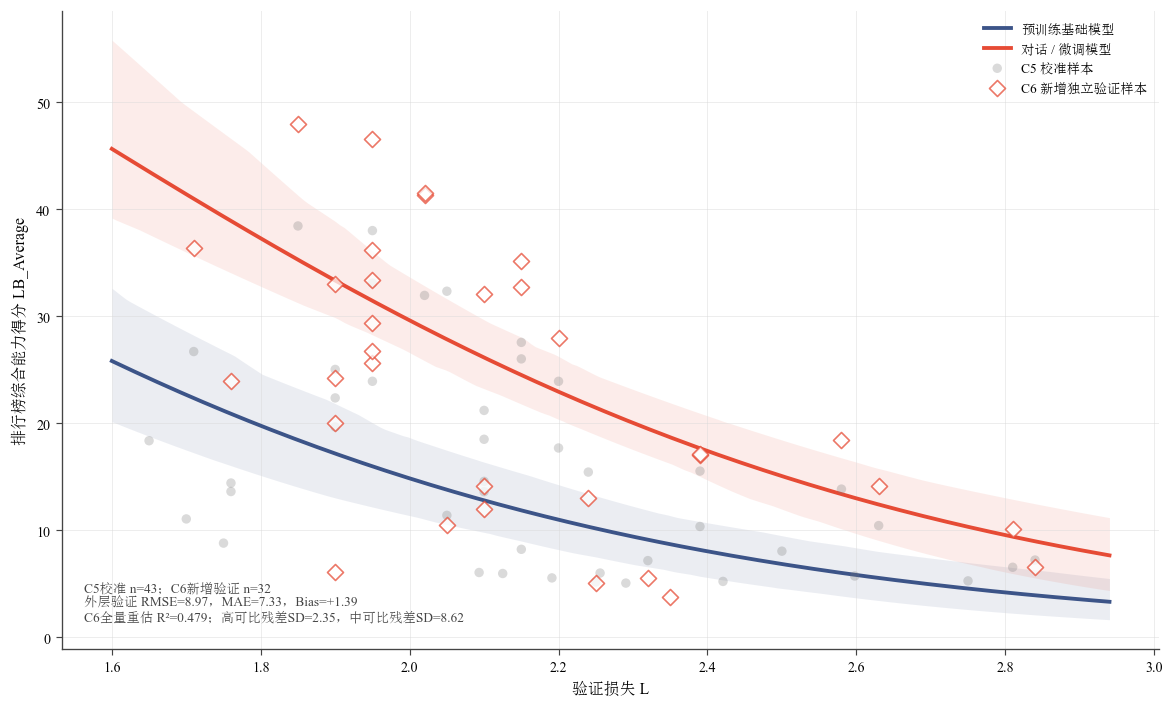

In [24]:
# ============ 5. Loss-Benchmark：自适应桥接 + C5/C6 外层验证 ============
L0 = 2.5

def prep_bridge(df):
    d = df.copy()
    d['chat'] = d['Model'].astype(str).str.lower().str.contains('instruct|-it$|chat|-it-|orpo|dpo').astype(float)
    d['tier'] = np.where(d['Loss_Comparability'].astype(str).str.startswith('High'), '高可比', '中可比')
    d['w_prior'] = np.where(d['tier'] == '高可比', 1.0, 0.5)
    d['Val_Loss'] = pd.to_numeric(d['Val_Loss'], errors='coerce'); d['LB_Average'] = pd.to_numeric(d['LB_Average'], errors='coerce')
    return d.dropna(subset=['Val_Loss','LB_Average']).reset_index(drop=True)

def bridge(th, L, chat):
    return 100 * expit(th[0] + th[1] * (L0 - np.asarray(L, float)) + th[2] * np.asarray(chat, float))

def fit_bridge_weighted(d, w, x0=None):
    if x0 is None: x0 = [-2.0, 3.0, 0.5]
    return least_squares(lambda th: np.sqrt(np.asarray(w, float)) * (bridge(th, d['Val_Loss'], d['chat']) - d['LB_Average']), x0).x

def fit_bridge_adaptive(d, pooled_prior=5.0, n_iter=4):
    w = d['w_prior'].values.astype(float).copy(); th = fit_bridge_weighted(d, w)
    for _ in range(n_iter):
        rr = d['LB_Average'].values - bridge(th, d['Val_Loss'], d['chat']); pv = float(np.mean(rr ** 2)); inv = np.zeros(len(d), float)
        for tier in d['tier'].unique():
            mask = (d['tier'].values == tier); v = (np.sum(rr[mask] ** 2) + pooled_prior * pv) / (mask.sum() + pooled_prior)
            inv[mask] = 1 / max(v, 1e-6)
        w = d['w_prior'].values * inv; w = w / max(w.max(), 1e-12); th = fit_bridge_weighted(d, w, th)
    return th, w

# ---- C5 校准；C6 新增模型外层验证 ----
B5 = prep_bridge(C5); B6 = prep_bridge(C6)
name5 = set(B5['Model'].astype(str).str.strip().str.lower())
B6['is_new_vs_C5'] = ~B6['Model'].astype(str).str.strip().str.lower().isin(name5)
B_EXT = B6[B6['is_new_vs_C5']].copy()
if len(B_EXT) < 5:
    raise RuntimeError('C6 相对 C5 的新增独立验证样本不足（<5），请检查 C5/C6 模型名称映射。')
TH_C5, W_C5 = fit_bridge_adaptive(B5)
B_EXT['pred_C5'] = bridge(TH_C5, B_EXT['Val_Loss'], B_EXT['chat']); B_EXT['res_C5'] = B_EXT['LB_Average'] - B_EXT['pred_C5']
EXT_RMSE = float(np.sqrt(np.mean(B_EXT['res_C5'] ** 2))); EXT_MAE = float(np.mean(np.abs(B_EXT['res_C5']))); EXT_BIAS = float(B_EXT['res_C5'].mean())
print('C5 校准 n=%d；C6 新增独立验证 n=%d：RMSE=%.2f，MAE=%.2f，Bias=%+.2f' % (len(B5), len(B_EXT), EXT_RMSE, EXT_MAE, EXT_BIAS))

# 外层验证完成后，用 C6 全量重估最终桥接
B = B6.copy(); TH_B, W_B = fit_bridge_adaptive(B); B['w'] = W_B
B['pred'] = bridge(TH_B, B['Val_Loss'], B['chat']); B['res'] = B['LB_Average'] - B['pred']
SIG = B.groupby('tier')['res'].std().to_dict(); R2b = 1 - (B['res'] ** 2).sum() / ((B['LB_Average'] - B['LB_Average'].mean()) ** 2).sum()
# C5 -> C6 参数漂移用于诊断，不参与模型选择
TH_SHIFT = TH_B - TH_C5
print('C6 全量重估桥接：S=100 sigma(%.3f + %.3f(2.5-L) + %.3f chat)，R2=%.3f；tier residual std=%s' % (TH_B[0], TH_B[1], TH_B[2], R2b, {k: round(v, 2) for k, v in SIG.items()}))
print('C5→C6 参数漂移 Δtheta =', np.round(TH_SHIFT, 4))

# 自适应 Bootstrap：每次重采样均重新估计异方差权重
boot_list = []
for ii in (RNG.integers(0, len(B), len(B)) for _ in range(N_BOOT)):
    ds = B.iloc[ii].reset_index(drop=True); thb, _ = fit_bridge_adaptive(ds); boot_list.append(thb)
BOOT_B = np.asarray(boot_list)
B.to_csv(TAB / 'bridge_fit_c6_full.csv', index=False, encoding='utf-8-sig')
B_EXT.to_csv(TAB / 'bridge_external_validation_c6_new.csv', index=False, encoding='utf-8-sig')
json.dump({'theta_c5': TH_C5.tolist(), 'theta_c6_full': TH_B.tolist(), 'theta_shift': TH_SHIFT.tolist(), 'L0': L0, 'sigma_tier': SIG, 'R2_full': float(R2b), 'external_rmse': EXT_RMSE, 'external_mae': EXT_MAE, 'external_bias': EXT_BIAS, 'n_c5': len(B5), 'n_c6_new': len(B_EXT), 'boot': BOOT_B.tolist()}, open(TAB / 'bridge_params.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1)

# ============ 问题三接口：L*(C) 连续化 ============
Q3_OPT = Q3['optimal_configs_default_Lctx']; COST_MAIN = '指数型'; COST_SENS = ['指数型', '幂函数型', '对数渐进型']
def extract_q3_curve(cost_name):
    rows = []
    for c_key, block in Q3_OPT.items():
        C = float(c_key)
        if cost_name not in block: continue
        cfg = block[cost_name]['executable']; rows.append({'C': C, 'loss': float(cfg['loss']), 'N': float(cfg['N']), 'D': float(cfg['D']), 'Q': float(cfg['Q'])})
    df = pd.DataFrame(rows).sort_values('C').reset_index(drop=True)
    if len(df) < 2: raise RuntimeError(f'问题三接口中成本函数 {cost_name} 的有效预算点不足')
    return df
Q3_CURVES = {c: extract_q3_curve(c) for c in COST_SENS if all(c in v for v in Q3_OPT.values())}; Q3_MAIN = Q3_CURVES[COST_MAIN]
C_curve = Q3_MAIN['C'].values.astype(float); L_curve = Q3_MAIN['loss'].values.astype(float); E_q3 = float(Q3['inputs']['classic_law']['E'])
gap = L_curve - E_q3
if np.any(gap <= 0): raise RuntimeError('Q3 最优 Loss 已低于/等于不可约损失 E，无法进行受约束幂律外推')
coef = np.polyfit(np.log(C_curve), np.log(gap), 1); eta_q3 = float(max(-coef[0], 1e-6)); K_q3 = float(np.exp(coef[1])); C_MIN_Q3 = float(C_curve.min()); C_MAX_Q3 = float(C_curve.max())

def L_star(C, cost_name=COST_MAIN):
    C = np.asarray(C, dtype=float); scalar = (C.ndim == 0); C1 = np.atleast_1d(C)
    df = Q3_MAIN if cost_name == COST_MAIN else Q3_CURVES[cost_name]; cc = df['C'].values.astype(float); ll = df['loss'].values.astype(float)
    if cost_name == COST_MAIN: E, K, eta = E_q3, K_q3, eta_q3
    else:
        gg = ll - E_q3
        if np.all(gg > 0): cf = np.polyfit(np.log(cc), np.log(gg), 1); eta = float(max(-cf[0], 1e-6)); K = float(np.exp(cf[1]))
        else: eta, K = eta_q3, K_q3
        E = E_q3
    out = np.empty_like(C1, dtype=float); inside = (C1 >= cc.min()) & (C1 <= cc.max()); high = C1 > cc.max(); low = C1 < cc.min()
    if inside.any(): out[inside] = np.interp(np.log10(C1[inside]), np.log10(cc), ll)
    if high.any(): out[high] = E + K * C1[high] ** (-eta)
    if low.any(): out[low] = ll[0]
    return float(out[0]) if scalar else out

def delta_L_star(C0, C1, cost_name=COST_MAIN): return np.asarray(L_star(C0, cost_name)) - np.asarray(L_star(C1, cost_name))
def anchored_score(F0, dL, beta_L=None):
    beta_L = TH_B[1] if beta_L is None else beta_L
    return 100 * expit(logit(np.clip(np.asarray(F0, float) / 100, 1e-4, 1 - 1e-4)) + beta_L * np.asarray(dL, float))
print('\nQ3→Q4 正式接口：只使用 ΔL* 的锚定增量桥接；不输出绝对 L*→S* 映射。')
print('Q3 主成本=%s；预算范围 [%.1e, %.1e]；高算力外推 L*(C)=%.4f+%.4g*C^(-%.4f)' % (COST_MAIN, C_MIN_Q3, C_MAX_Q3, E_q3, K_q3, eta_q3))

# ---- 图 9：C5 校准 / C6 新增验证 / C6 全量桥接 ----
fig, ax = plt.subplots(figsize=(11.8, 6.9)); Ls = np.linspace(B['Val_Loss'].min() - .05, B['Val_Loss'].max() + .10, 220)
for chat, c, label in [(0, C_NAVY, '预训练基础模型'), (1, C_CORAL, '对话 / 微调模型')]:
    mid = bridge(TH_B, Ls, chat); fan = np.array([bridge(th, Ls, chat) for th in BOOT_B]); lo, hi = np.percentile(fan, [2.5, 97.5], axis=0)
    ax.fill_between(Ls, lo, hi, color=c, alpha=.10, lw=0); ax.plot(Ls, mid, color=c, lw=2.3, label=label)
cal_names = set(B5['Model'].astype(str).str.strip().str.lower()); bcal = B[B['Model'].astype(str).str.strip().str.lower().isin(cal_names)]
for d, marker, alpha, lab in [(bcal, 'o', .28, 'C5 校准样本'), (B_EXT, 'D', .75, 'C6 新增独立验证样本')]:
    ax.scatter(d['Val_Loss'], d['LB_Average'], s=32 if marker=='o' else 46, marker=marker, facecolor='white' if marker=='D' else C_GREY, edgecolor=C_CORAL if marker=='D' else 'none', lw=1.0, alpha=alpha, zorder=3, label=lab)
ax.set_xlabel('验证损失 L'); ax.set_ylabel('排行榜综合能力得分 LB_Average'); nature_ax(ax, 'both'); ax.legend(frameon=False, loc='upper right')
ax.text(.02, .04, 'C5校准 n=%d；C6新增验证 n=%d\n外层验证 RMSE=%.2f，MAE=%.2f，Bias=%+.2f\nC6全量重估 R²=%.3f；高可比残差SD=%.2f，中可比残差SD=%.2f' % (len(B5), len(B_EXT), EXT_RMSE, EXT_MAE, EXT_BIAS, R2b, SIG.get('高可比', np.nan), SIG.get('中可比', np.nan)), transform=ax.transAxes, fontsize=8.0, va='bottom', color='#444444')
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig09_loss_benchmark_external_validation_v8.png'); plt.show()


## 6. 未来 12 / 24 个月前沿：新版候选统一竞赛 + 多期限样本外验证

### 6.1 新版候选
最终预测只在以下当前模型之间竞争：

- **EARF**：$\operatorname{logit}(F/100)=a+b\ln(1+M(\tau))+c\tau$；
- **Compute-Q90**：训练算力 q90 前沿生产函数；
- **DATF-Q90**：加入发布—提交延迟的双时间轴 q90 模型；
- **Non-negative stacking**：对上述候选的 OOF 预测做非负、和为 1 的约束融合。

### 6.2 多期限 rolling-origin
滚动回测同时使用 3、6、9 个月预测期限。每个预测原点只使用此前数据拟合，并在相同 OOF 样本上比较各单模型与 stacking 的 MAE。最终模型直接取统一 OOF 样本上 MAE 最小者。

### 6.3 长期限不确定性
12/24 月预测区间由三部分组成：
1. 模型参数 Bootstrap；
2. 变化点后算力增长率的不确定性与三种情景；
3. 3/6/9 月 rolling-origin 残差随期限扩张形成的经验误差项。

因此 24 个月不再复用 3 个月的固定误差半径；长周期区间明确称为 **horizon-expanded empirical interval**，不宣称严格 i.i.d. conformal 覆盖保证。



[pretrained] n=241, 日期=2024-06-08 ~ 2025-03-09, MIN_LB=20
  horizon=3 月：有效 folds=4
  horizon=6 月：有效 folds=1
  horizon=9 月：有效 folds=0

[chat/finetuned] n=2257, 日期=2024-06-09 ~ 2025-03-13, MIN_LB=20
  horizon=3 月：有效 folds=4
  horizon=6 月：有效 folds=1
  horizon=9 月：有效 folds=0

rolling-origin 总预测记录： 30


类型              h_target  模型         
chat/finetuned  3         Compute-Q90    4
                          DATF-Q90       4
                          EARF           4
                6         Compute-Q90    1
                          DATF-Q90       1
                          EARF           1
pretrained      3         Compute-Q90    4
                          DATF-Q90       4
                          EARF           4
                6         Compute-Q90    1
                          DATF-Q90       1
                          EARF           1
Name: folds, dtype: int64

多期限 rolling-origin 回测:


,类型,h_target,模型,MAE,RMSE,folds
0,chat/finetuned,3,Compute-Q90,3.1625,3.1677,4
1,chat/finetuned,3,DATF-Q90,5.3325,5.8933,4
2,chat/finetuned,3,EARF,12.1859,24.3718,4
3,chat/finetuned,6,Compute-Q90,0.0841,0.0841,1
4,chat/finetuned,6,DATF-Q90,5.8861,5.8861,1
5,chat/finetuned,6,EARF,48.7687,48.7687,1
6,pretrained,3,Compute-Q90,3.9317,4.1931,4
7,pretrained,3,DATF-Q90,6.0048,6.7008,4
8,pretrained,3,EARF,14.4866,16.8495,4
9,pretrained,6,Compute-Q90,3.8938,3.8938,1


pretrained 最终选择 = Compute-Q90；OOF MAE=3.924；候选={'EARF': 15.782, 'Compute-Q90': 3.924, 'DATF-Q90': 6.587, 'NonNeg-Stack': 3.924}；stack权重={'EARF': 0.0, 'Compute-Q90': 1.0, 'DATF-Q90': 0.0}
chat/finetuned 最终选择 = NonNeg-Stack；OOF MAE=2.369；候选={'EARF': 19.502, 'Compute-Q90': 2.547, 'DATF-Q90': 5.443, 'NonNeg-Stack': 2.369}；stack权重={'EARF': 0.058, 'Compute-Q90': 0.942, 'DATF-Q90': 0.0}

未来前沿预测:


,类型,最终模型,情景,月数,中位数,Bootstrap+情景 5%,Bootstrap+情景 95%,期限扩张经验下界,期限扩张经验上界,期限扩张q
0,pretrained,Compute-Q90,延续（数据驱动最近段）,12,49.3500,45.3900,56.0100,38.0100,68.8900,12.8900
1,pretrained,Compute-Q90,延续（数据驱动最近段）,24,60.6400,52.7300,72.5300,38.0100,90.7600,18.2300
2,pretrained,Compute-Q90,放缓（对数增长率减半）,12,48.3800,44.8000,54.9800,38.0100,67.8700,12.8900
3,pretrained,Compute-Q90,放缓（对数增长率减半）,24,58.7900,51.7400,70.8000,38.0100,89.0200,18.2300
4,pretrained,Compute-Q90,停滞（前沿算力不增长）,12,47.8200,44.2600,54.3000,38.0100,67.1900,12.8900
5,pretrained,Compute-Q90,停滞（前沿算力不增长）,24,57.6600,50.6300,69.7900,38.0100,88.0200,18.2300
6,chat/finetuned,NonNeg-Stack,延续（数据驱动最近段）,12,62.3100,51.2300,68.4600,51.2300,74.8900,6.4300
7,chat/finetuned,NonNeg-Stack,延续（数据驱动最近段）,24,72.1000,51.2300,81.7000,51.2300,90.7900,9.0900
8,chat/finetuned,NonNeg-Stack,放缓（对数增长率减半）,12,61.4200,51.2300,67.4600,51.2300,73.8900,6.4300
9,chat/finetuned,NonNeg-Stack,放缓（对数增长率减半）,24,70.6800,51.2300,80.4700,51.2300,89.5700,9.0900



Q3→Q4 锚定 ΔL* 交叉核对:


,类型,情景,月数,当前前沿,ΔL中位,锚定Loss通道前沿,锚定Loss通道增量,最终模型总增量,两通道差额_仅作未解释项
0,pretrained,延续（数据驱动最近段）,12,38.0100,0.0100,38.3400,0.3300,11.3400,11.0100
1,pretrained,延续（数据驱动最近段）,24,38.0100,0.0200,38.6800,0.6700,22.6300,21.9600
2,pretrained,放缓（对数增长率减半）,12,38.0100,0.0000,38.1800,0.1700,10.3700,10.2000
3,pretrained,放缓（对数增长率减半）,24,38.0100,0.0100,38.3600,0.3500,20.7800,20.4300
4,pretrained,停滞（前沿算力不增长）,12,38.0100,0.0000,38.0100,0.0000,9.8100,9.8100
5,pretrained,停滞（前沿算力不增长）,24,38.0100,0.0000,38.0100,0.0000,19.6500,19.6500
6,chat/finetuned,延续（数据驱动最近段）,12,51.2300,0.0100,51.6000,0.3700,11.0800,10.7100
7,chat/finetuned,延续（数据驱动最近段）,24,51.2300,0.0200,51.9400,0.7100,20.8700,20.1600
8,chat/finetuned,放缓（对数增长率减半）,12,51.2300,0.0000,51.4200,0.1900,10.1900,10.0000
9,chat/finetuned,放缓（对数增长率减半）,24,51.2300,0.0100,51.6100,0.3800,19.4500,19.0800


MERG NOT subset; don't know how to subset; dropped


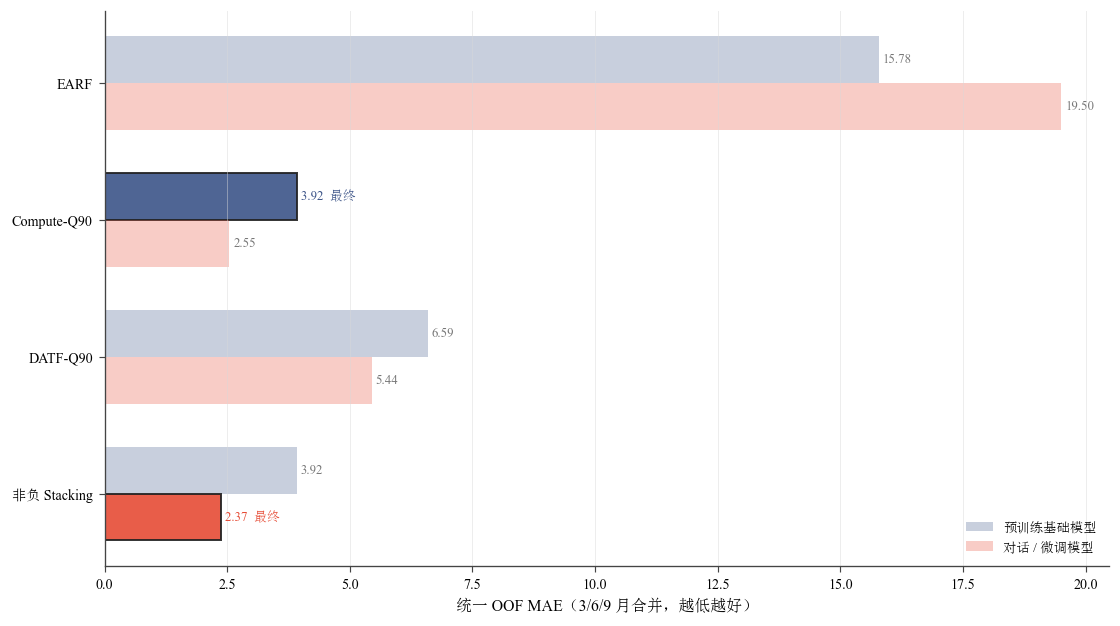

MERG NOT subset; don't know how to subset; dropped


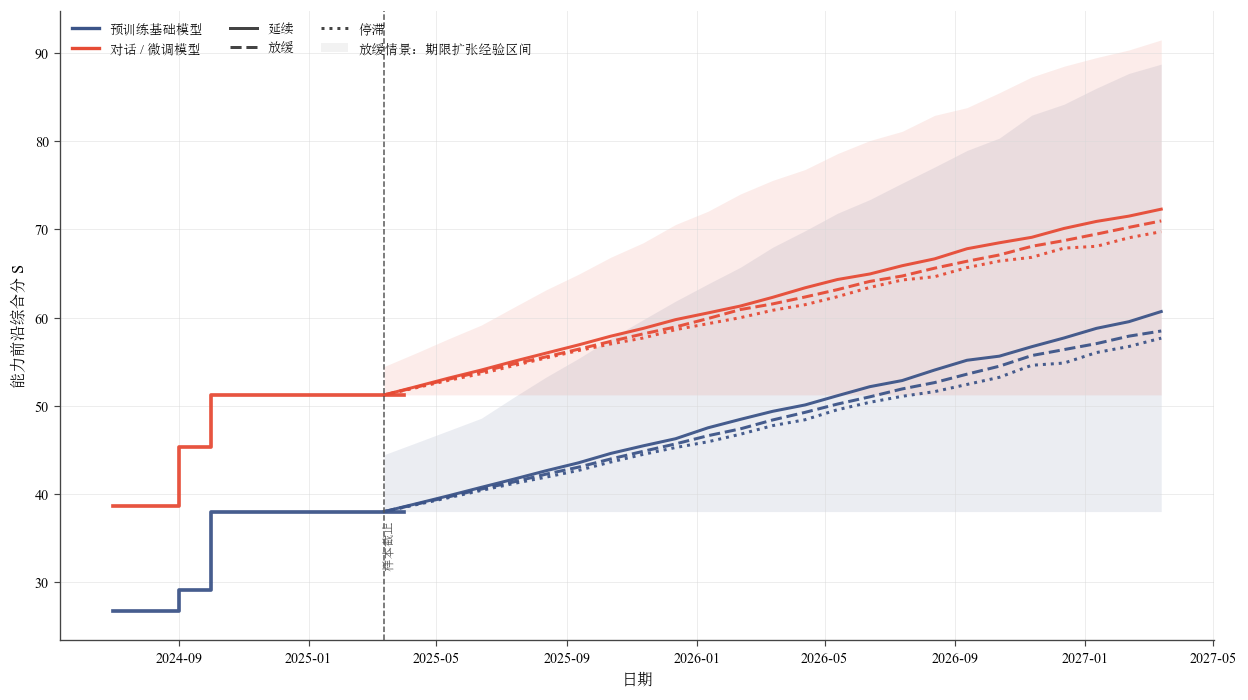

In [25]:
# ============ 6. 新版前沿预测：多期限 OOF 竞赛 + 非负 stacking ============
H = [12, 24]; BACKTEST_H = [3, 6, 9]; tau_end = float(LB['tau'].max()); last_date = LB['date_sub'].max(); FC = []

def monthly_frontier(df, end_date=None):
    d = df.copy()
    if end_date is not None: d = d[d['date_sub'] <= pd.Timestamp(end_date)]
    d = d.sort_values('date_sub'); p = d['date_sub'].dt.to_period('M')
    grp = d.groupby(p).agg(month_max=('S', 'max'), n=('S', 'size')).sort_index(); grp['F'] = grp['month_max'].cummax(); grp['M'] = grp['n'].cumsum()
    grp['tau'] = np.array([(x.to_timestamp(how='end') - T0).days / 30.4375 for x in grp.index]); return grp

def fit_EARF(grp):
    X = np.column_stack([np.ones(len(grp)), np.log1p(grp['M'].values), grp['tau'].values]); return np.linalg.lstsq(X, logit(np.clip(grp['F'].values / 100, 1e-3, 1 - 1e-3)), rcond=None)[0]
def recent_rate(grp, k=6): return float(max(1e-6, grp['n'].tail(min(k, len(grp))).median()))
def pred_EARF(b, M_now, t_future, t_now, rate):
    M_future = M_now + rate * np.maximum(np.asarray(t_future) - t_now, 0); return 100 * expit(b[0] + b[1] * np.log1p(M_future) + b[2] * np.asarray(t_future))

def estimate_G_at(cut):
    d = OW[OW['date_pub4'] <= pd.Timestamp(cut)].copy()
    if len(d) < 30: return 1.0
    yr_cut = pd.Timestamp(cut).year + pd.Timestamp(cut).dayofyear / 365.25; recent = d[d.yr >= yr_cut - 2.5]
    if len(recent) < 25: recent = d.tail(max(25, int(.45 * len(d))))
    X = np.column_stack([np.ones(len(recent)), recent['yr'] - 2020]); b = quantreg(X, recent['log10C'].values, .9); return float(np.clip(10 ** b[1], .6, 50))

def fit_B_candidates(mc):
    z = np.log(mc['C']); center = float(z.median()); zc = z - center; chat = (mc['type'] == 'chat/finetuned').astype(float).values; y = mc['y'].values
    X = np.column_stack([np.ones(len(mc)), zc, mc['tau_pub'], chat]); q = quantreg(X, y, .9)
    Xd = np.column_stack([np.ones(len(mc)), zc, mc['tau_pub'], mc['lag_month'], chat]); dual = quantreg(Xd, y, .9)
    return {'Compute-Q90': q, 'DATF-Q90': dual}

def point_B(F_now, h, G, b):
    beta, gamma = float(b[1]), float(b[2])
    return float(max(F_now, 100 * expit(logit(F_now / 100) + beta * (h / 12) * np.log(G) + gamma * h))) if beta > 0 else np.nan

# ---------- 3/6/9 个月 rolling-origin ----------
# ---------- 多期限 rolling-origin：依据真实可用时间跨度动态构造 ----------
CAND = ['EARF', 'Compute-Q90', 'DATF-Q90']
BT = []

for g in ('pretrained', 'chat/finetuned'):

    dall = LB[
        (LB['type'] == g) &
        (LB['open_strict'])
    ].copy().sort_values('date_sub').reset_index(drop=True)

    if len(dall) == 0:
        continue

    # 不再强制“最早日期后再等待 6 个月”
    # 样本较少时自动降低最小训练样本门槛
    MIN_LB = max(
        8,
        min(20, len(dall) // 5)
    )

    # Compute-Q90 / DATF-Q90 所需的 C4 历史样本
    MIN_MC = 12

    # 使用真实出现过数据的月份作为候选 cut
    month_cuts = sorted(
        dall['date_sub']
        .dropna()
        .dt.to_period('M')
        .unique()
    )

    month_cuts = [
        pd.Period(x, freq='M').to_timestamp(how='end')
        for x in month_cuts
    ]

    print(
        f'\n[{g}] n={len(dall)}, '
        f'日期={dall.date_sub.min().date()} ~ '
        f'{dall.date_sub.max().date()}, '
        f'MIN_LB={MIN_LB}'
    )

    for htar in BACKTEST_H:

        fold_count = 0

        for cut in month_cuts:

            target = cut + pd.DateOffset(months=int(htar))

            # 必须是真正的历史回测：
            # target 不能越过样本截止日
            if target > last_date:
                continue

            train = dall[dall['date_sub'] <= cut].copy()

            if len(train) < MIN_LB:
                continue

            # cut 后到 target 之间必须确实有新模型出现
            future_obs = dall[
                (dall['date_sub'] > cut) &
                (dall['date_sub'] <= target)
            ]

            if future_obs.empty:
                continue

            # ---------- EARF ----------
            try:
                gr = monthly_frontier(train)

                if len(gr) < 3:
                    continue

                F0 = float(gr['F'].iloc[-1])
                t0 = float(gr['tau'].iloc[-1])

                # 使用真实天数计算预测跨度
                h = (target - cut).days / 30.4375

                be = fit_EARF(gr)

                pE = max(
                    F0,
                    float(
                        pred_EARF(
                            be,
                            float(gr['M'].iloc[-1]),
                            t0 + h,
                            t0,
                            recent_rate(gr)
                        )
                    )
                )

            except Exception:
                continue

            # target 时刻真实累计前沿
            actual_pool = dall[
                dall['date_sub'] <= target
            ]

            if actual_pool.empty:
                continue

            actual = float(
                actual_pool['S'].max()
            )

            # ---------- Compute-Q90 / DATF-Q90 ----------
            mc = MC[
                MC['date_sub'] <= cut
            ].copy()

            if len(mc) < MIN_MC:
                continue

            try:
                G = estimate_G_at(cut)
                bb = fit_B_candidates(mc)

                pCQ = point_B(
                    F0,
                    h,
                    G,
                    bb['Compute-Q90']
                )

                pDATF = point_B(
                    F0,
                    h,
                    G,
                    bb['DATF-Q90']
                )

            except Exception:
                continue

            preds = {
                'EARF': pE,
                'Compute-Q90': pCQ,
                'DATF-Q90': pDATF
            }

            # 三个模型必须在同一个 fold 上同时有效，
            # 保证 OOF 比较公平
            if not all(
                np.isfinite(preds[m])
                for m in CAND
            ):
                continue

            for name in CAND:

                err = float(
                    preds[name] - actual
                )

                BT.append({
                    '类型': g,
                    'cut': cut,
                    'target': target,
                    'h_target': int(htar),
                    'h_month': float(h),
                    '模型': name,
                    'pred': float(preds[name]),
                    'actual': actual,
                    'error': err,
                    'abs_error': abs(err)
                })

            fold_count += 1

        print(
            f'  horizon={htar} 月：'
            f'有效 folds={fold_count}'
        )


BTDF = pd.DataFrame(BT)

if BTDF.empty:
    raise RuntimeError(
        'rolling-origin 仍无有效历史回测折。'
        '请查看上方各 horizon 的 folds 数；'
        '不要人为生成不存在的历史数据。'
    )

print(
    '\nrolling-origin 总预测记录：',
    len(BTDF)
)

display(
    BTDF.groupby(
        ['类型', 'h_target', '模型']
    ).size().rename('folds')
)

BTDF.to_csv(
    TAB / 'rolling_origin_multihorizon.csv',
    index=False,
    encoding='utf-8-sig'
)
BTDF.to_csv(TAB / 'rolling_origin_multihorizon.csv', index=False, encoding='utf-8-sig')
CV_H = BTDF.groupby(['类型', 'h_target', '模型']).agg(MAE=('abs_error', 'mean'), RMSE=('error', lambda x: float(np.sqrt(np.mean(np.square(x))))), folds=('error', 'size')).reset_index()
print('多期限 rolling-origin 回测:'); display(CV_H)

# ---------- 非负 stacking 与统一 OOF 竞赛 ----------
def fit_simplex_stack(X, y):
    m = X.shape[1]; w0 = np.ones(m) / m
    obj = lambda w: float(np.mean(np.sqrt((X @ w - y) ** 2 + 1e-6)))
    res = minimize(obj, w0, method='SLSQP', bounds=[(0.0, 1.0)] * m, constraints=[{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}], options={'maxiter': 1000, 'ftol': 1e-10})
    if not res.success: raise RuntimeError('非负 stacking 优化失败: ' + str(res.message))
    w = np.clip(res.x, 0, 1); return w / w.sum()

FINAL_WEIGHTS = {}; FINAL_CHOICE = {}; SELECT_ROWS = []; OOF_FINAL = {}
for g in ('pretrained', 'chat/finetuned'):
    z = BTDF[BTDF.类型 == g].pivot_table(index=['cut','target','h_target','actual'], columns='模型', values='pred').dropna(subset=CAND).reset_index()
    if len(z) < 3: raise RuntimeError(f'{g} 在三个新版候选共同 OOF 样本上不足 3 个，无法进行公平模型竞赛。')
    X = z[CAND].values.astype(float); y = z['actual'].values.astype(float); w_stack = fit_simplex_stack(X, y); stack_pred = X @ w_stack
    scores = {m: float(np.mean(np.abs(z[m].values - y))) for m in CAND}; scores['NonNeg-Stack'] = float(np.mean(np.abs(stack_pred - y)))
    choice = min(scores, key=scores.get); FINAL_CHOICE[g] = choice
    if choice == 'NonNeg-Stack': weights = {m: float(w) for m, w in zip(CAND, w_stack)}; pred_final = stack_pred
    else: weights = {m: (1.0 if m == choice else 0.0) for m in CAND}; pred_final = z[choice].values
    FINAL_WEIGHTS[g] = weights; zz = z[['cut','target','h_target','actual']].copy(); zz['pred_final'] = pred_final; zz['abs_error'] = np.abs(pred_final - y); OOF_FINAL[g] = zz
    for m in CAND: SELECT_ROWS.append({'类型': g, '模型': m, 'OOF_MAE': scores[m], '最终选择': choice == m, '最终权重': weights[m]})
    SELECT_ROWS.append({'类型': g, '模型': 'NonNeg-Stack', 'OOF_MAE': scores['NonNeg-Stack'], '最终选择': choice == 'NonNeg-Stack', '最终权重': 1.0 if choice == 'NonNeg-Stack' else 0.0})
    print('%s 最终选择 = %s；OOF MAE=%.3f；候选=%s；stack权重=%s' % (g, choice, scores[choice], {k: round(v,3) for k,v in scores.items()}, {k: round(v,3) for k,v in zip(CAND,w_stack)}))
SELECTDF = pd.DataFrame(SELECT_ROWS); SELECTDF.to_csv(TAB / 'new_model_oof_competition.csv', index=False, encoding='utf-8-sig')

# ---------- 全数据拟合 + Bootstrap ----------
def boot_EARF(df, n=N_BOOT):
    out = []
    for _ in range(n):
        ds = df.iloc[RNG.integers(0, len(df), len(df))]; gr = monthly_frontier(ds)
        if len(gr) < 4: continue
        out.append(np.r_[fit_EARF(gr), recent_rate(gr), gr['M'].iloc[-1], gr['tau'].iloc[-1]])
    return np.asarray(out)
A_RES = {}
for g in ('pretrained', 'chat/finetuned'):
    d = LB[(LB.type == g) & LB.open_strict]; gr = monthly_frontier(d); A_RES[g] = {'grp': gr, 'F_now': float(gr.F.iloc[-1]), 'EARF': fit_EARF(gr), 'boot_EARF': boot_EARF(d)}
BBOOT = {'Compute-Q90': bo_c_q, 'DATF-Q90': bo_dual}
G_phys_ci = GR['变化点后']['ci_mult']; sd_lnG = max(0.02, (np.log(max(G_phys_ci[1], 1e-6)) - np.log(max(G_phys_ci[0], 1e-6))) / (2 * 1.96))
def draw_G(sname, n):
    G = SCEN[sname]
    if '停滞' in sname: return np.ones(n)
    return np.exp(RNG.normal(np.log(G), sd_lnG * (.5 if '放缓' in sname else 1.0), n))
def dist_candidate(g, name, h, sname, n=2500):
    ar = A_RES[g]; F0 = ar['F_now']; t0 = float(ar['grp'].tau.iloc[-1])
    if name == 'EARF':
        bo = ar['boot_EARF']; ii = RNG.integers(0, len(bo), n); vals = []
        for row in bo[ii]: vals.append(max(F0, float(pred_EARF(row[:3], row[4], t0 + h, row[5], row[3]))))
        return np.asarray(vals)
    bo = BBOOT[name]; ii = RNG.integers(0, len(bo), n); bb = bo[ii]; gp = draw_G(sname, n); yy = logit(F0 / 100) + bb[:, 1] * (h / 12) * np.log(gp) + bb[:, 2] * h
    return np.maximum(F0, 100 * expit(yy))

# ---------- 多期限经验残差扩张 ----------
def empirical_q(x, alpha=.10):
    r = np.sort(np.asarray(x, float))
    if len(r) == 0: return np.nan
    k = min(len(r), int(np.ceil((len(r) + 1) * (1 - alpha)))); return float(r[max(k - 1, 0)])
CAL = {}
for g in OOF_FINAL:
    qh = {}
    for hh, d in OOF_FINAL[g].groupby('h_target'): qh[int(hh)] = empirical_q(d['abs_error'].values, ALPHA_PI)
    CAL[g] = {'q_by_horizon': qh}

def horizon_q(g, h):
    qh = CAL[g]['q_by_horizon']; vals = []
    for hh, q in qh.items():
        if np.isfinite(q): vals.append(q * np.sqrt(max(float(h), hh) / hh))
    return float(max(vals)) if vals else 0.0

# ---------- 未来 12/24 月预测 ----------
MIX = {}
for g in ('pretrained', 'chat/finetuned'):
    F0 = A_RES[g]['F_now']
    for sname in SCEN:
        for h in H:
            parts = []
            for m, w in FINAL_WEIGHTS[g].items():
                if w <= 0: continue
                n = max(1, int(round(5000 * w))); parts.append(dist_candidate(g, m, h, sname, n))
            mix = np.concatenate(parts); MIX[(g, sname, h)] = mix; qcal = horizon_q(g, h)
            lo = max(F0, float(np.percentile(mix, 5) - qcal)); hi = min(100, float(np.percentile(mix, 95) + qcal))
            FC.append({'类型': g, '最终模型': FINAL_CHOICE[g], '情景': sname, '月数': h, '中位数': float(np.median(mix)), 'Bootstrap+情景 5%': float(np.percentile(mix,5)), 'Bootstrap+情景 95%': float(np.percentile(mix,95)), '期限扩张经验下界': lo, '期限扩张经验上界': hi, '期限扩张q': qcal})
FCDF = pd.DataFrame(FC); FCDF.to_csv(TAB / 'frontier_forecast_v8.csv', index=False, encoding='utf-8-sig'); print('\n未来前沿预测:'); display(FCDF.round(2))

# ---------- Q3→Q4：锚定 ΔL* 通道交叉核对 ----------
rows = []
for g in ('pretrained', 'chat/finetuned'):
    F0 = A_RES[g]['F_now']
    for sname in SCEN:
        for h in H:
            n = 3000; gp = draw_G(sname, n); C1 = C_ANCHOR_LB * gp ** (h / 12); dL = L_star(C_ANCHOR_LB) - L_star(C1)
            bb = BOOT_B[RNG.integers(0, len(BOOT_B), n), 1]; S_loss = anchored_score(F0, dL, bb); total = float(np.median(MIX[(g, sname, h)]))
            rows.append({'类型': g, '情景': sname, '月数': h, '当前前沿': F0, 'ΔL中位': float(np.median(dL)), '锚定Loss通道前沿': float(np.median(S_loss)), '锚定Loss通道增量': float(np.median(S_loss)) - F0, '最终模型总增量': total - F0, '两通道差额_仅作未解释项': (total - F0) - (float(np.median(S_loss)) - F0)})
LOSSCH = pd.DataFrame(rows); LOSSCH.to_csv(TAB / 'anchored_delta_loss_bridge_crosscheck.csv', index=False, encoding='utf-8-sig'); print('\nQ3→Q4 锚定 ΔL* 交叉核对:'); display(LOSSCH.round(2))

# ---------- 阈值概率 ----------
THR = {'pretrained': [40,45,50,55], 'chat/finetuned': [55,60,65,70]}; PL = []
for g in THR:
    for h in H:
        for sname in SCEN:
            x = MIX[(g, sname, h)]
            for thr in THR[g]: PL.append({'类型': g, '月数': h, '情景': sname, '阈值': thr, 'P': float((x > thr).mean())})
PLDF = pd.DataFrame(PL); PLDF.to_csv(TAB / 'probability_ladder.csv', index=False, encoding='utf-8-sig')

# ---- 图 10：新版候选的 OOF 统一竞赛 ----
order = ['EARF','Compute-Q90','DATF-Q90','NonNeg-Stack']; y = np.arange(len(order)); hbar = .34
fig, ax = plt.subplots(figsize=(10.8, 6.0))
for off, g, c, label in [(-hbar/2,'pretrained',C_NAVY,'预训练基础模型'),(hbar/2,'chat/finetuned',C_CORAL,'对话 / 微调模型')]:
    d = SELECTDF[SELECTDF.类型 == g].set_index('模型').reindex(order); vals = d['OOF_MAE'].values
    bars = ax.barh(y + off, vals, height=hbar, color=c, alpha=.82, label=label)
    for i, (v, b) in enumerate(zip(vals, bars)):
        sel = bool(d['最终选择'].iloc[i]); b.set_alpha(.9 if sel else .28)
        if sel: b.set_edgecolor('#222222'); b.set_linewidth(1.2)
        ax.text(v + .08, i + off, f'{v:.2f}' + ('  最终' if sel else ''), va='center', fontsize=7.7, color=c if sel else '#777777')
ax.set_yticks(y); ax.set_yticklabels(['EARF','Compute-Q90','DATF-Q90','非负 Stacking']); ax.invert_yaxis(); ax.set_xlabel('统一 OOF MAE（3/6/9 月合并，越低越好）'); nature_ax(ax, 'x'); ax.legend(frameon=False, loc='lower right')
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig10_new_model_oof_competition_v8.png'); plt.show()

# ---- 图 11：两类模型未来前沿与算力情景 ----
fig, ax = plt.subplots(figsize=(12.4, 6.8)); hgrid = np.linspace(0, 24, 25); fut = np.array([last_date + pd.Timedelta(days=30.4375 * h) for h in hgrid])
styles = {'延续（数据驱动最近段）': '-', '放缓（对数增长率减半）': '--', '停滞（前沿算力不增长）': ':'}
for g, c in COL_TYPE.items():
    gr = A_RES[g]['grp']; actual_dates = [p.to_timestamp(how='end') for p in gr.index]; ax.step(actual_dates, gr.F, where='post', color=c, lw=2.2, alpha=.95); F0 = A_RES[g]['F_now']
    for sname in SCEN:
        med, lo, hi = [], [], []
        for h0 in hgrid:
            parts = [dist_candidate(g, m, h0, sname, max(100, int(1200 * w))) for m, w in FINAL_WEIGHTS[g].items() if w > 0]; xx = np.concatenate(parts); qcal = horizon_q(g, max(h0, 1))
            med.append(np.median(xx)); lo.append(max(F0, np.percentile(xx, 5) - qcal)); hi.append(min(100, np.percentile(xx, 95) + qcal))
        med, lo, hi = np.asarray(med), np.asarray(lo), np.asarray(hi); ax.plot(fut, med, color=c, lw=1.8, ls=styles[sname], alpha=.95)
        if '放缓' in sname: ax.fill_between(fut, lo, hi, color=c, alpha=.10, lw=0)
ax.axvline(last_date, color='#555555', lw=.9, ls='--'); ax.text(last_date, 31.0, ' 样本截止', rotation=90, va='bottom', fontsize=7.4, color='#555555')
ax.set_xlabel('日期'); ax.set_ylabel('能力前沿综合分 S'); nature_ax(ax, 'both')
handles = [Line2D([0],[0],color=C_NAVY,lw=2,label='预训练基础模型'), Line2D([0],[0],color=C_CORAL,lw=2,label='对话 / 微调模型'), Line2D([0],[0],color='#444',lw=1.8,ls='-',label='延续'), Line2D([0],[0],color='#444',lw=1.8,ls='--',label='放缓'), Line2D([0],[0],color='#444',lw=1.8,ls=':',label='停滞'), Patch(facecolor='#999999',alpha=.12,label='放缓情景：期限扩张经验区间')]
ax.legend(handles=handles, frameon=False, ncol=3, loc='upper left')
ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig11_future_frontier_multihorizon_v8.png'); plt.show()


## 7. 稳健性与消融

本节验证三类问题：

1. **口径稳健性**：严/宽开源口径、q=0.85/0.90/0.95、C1/C8 综合分、提交/发布/评测时间轴；
2. **结构辨识**：Compute-Q90 与 DATF-Q90 的系数稳定性、EARF/Compute-Q90/DATF-Q90/stacking 的多期限 OOF 误差；
3. **桥接外推稳健性**：C5 校准、C6 新增样本外层验证、C6 全量重估后的参数漂移与残差结构。

所有时间系数均按“非规模时间漂移”解释；若不同时间轴下系数变化明显，则将其视为识别不确定性，而不是强行解释为算法进步。


口径稳健性:


,类型,口径,n,gamma/月,年参数倍数
0,pretrained,严口径/提交/q=.90/C1,241,0.0231,1.9136
1,pretrained,宽口径,330,0.0206,1.7796
2,pretrained,q=.85,241,0.0241,2.0648
3,pretrained,q=.95,241,0.0100,1.3428
4,pretrained,C8重建 S_C8,118,0.0117,1.4263
5,pretrained,C8评测时间,118,0.0260,2.1800
6,pretrained,Epoch发布日期,57,0.0292,2.3053
7,chat/finetuned,严口径/提交/q=.90/C1,2257,0.0637,5.8092
8,chat/finetuned,宽口径,4222,0.0584,4.8940
9,chat/finetuned,q=.85,2257,0.0712,7.2116



新版候选样本外消融:


,类型,模型,OOF_MAE,最终选择,最终权重,多期限平均MAE,最少folds
7,chat/finetuned,NonNeg-Stack,2.3690,True,1.0000,NaN,NaN
5,chat/finetuned,Compute-Q90,2.5468,False,0.9425,1.6233,1.0000
6,chat/finetuned,DATF-Q90,5.4432,False,0.0000,5.6093,1.0000
4,chat/finetuned,EARF,19.5025,False,0.0575,30.4773,1.0000
1,pretrained,Compute-Q90,3.9241,True,1.0000,3.9127,1.0000
3,pretrained,NonNeg-Stack,3.9241,False,0.0000,NaN,NaN
2,pretrained,DATF-Q90,6.5867,False,0.0000,7.4595,1.0000
0,pretrained,EARF,15.7825,False,0.0000,17.7262,1.0000



逻辑收口状态:


,模块,当前方法,验证证据
0,规模—非规模贡献,C4 Training Compute 的 Compute-Q90 Shapley + 未解释项,三项占实际前沿变化比例直接报告，不截断
1,Loss–Benchmark,异方差自适应 Logistic；C5校准→C6新增外层验证→C6全量重估,"C6新增 RMSE=8.97, MAE=7.33"
2,预测器 pretrained,Compute-Q90,3/6/9 月统一 OOF MAE 最小
3,预测器 chat,NonNeg-Stack,3/6/9 月统一 OOF MAE 最小
4,Q3→Q4 接口,anchored ΔL* → ΔS,当前真实前沿 F0 为锚，仅传递 Loss 边际改善


MERG NOT subset; don't know how to subset; dropped


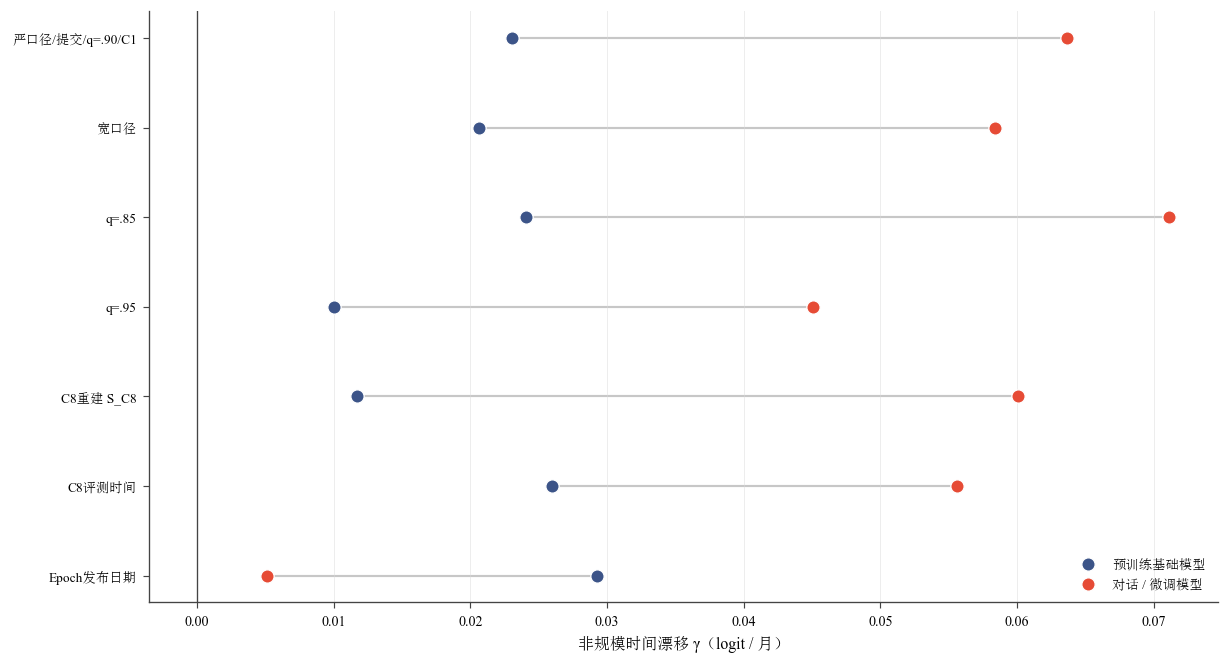

已保存 output_q4_v8/tables/q4_summary_v8.json


In [26]:
# ============ 7. 稳健性 + 消融 ============
def fit_gamma(df, q=.9, ycol='y', tcol='tau'):
    X = design(df['lnN'].values, df[tcol].values); b = quantreg(X, df[ycol].values, q); Nref = float(np.exp(np.median(df['lnN']))); bN = b[1] + 2 * b[2] * np.log(Nref)
    return b[3], float(np.exp(12 * b[3] / bN)) if bN > 0 else np.nan
LB['tau_pub'] = (LB['date_pub'] - T0).dt.days / 30.4375; LB['tau_eval'] = (LB['date_eval'] - T0).dt.days / 30.4375; LB['y_c8'] = logit(np.clip(LB['S_C8'] / 100, 1e-3, 1 - 1e-3))
rows = []
for g in ('pretrained','chat/finetuned'):
    d0 = LB[LB.type == g]
    variants = [('严口径/提交/q=.90/C1', d0[d0.open_strict], .9, 'y', 'tau'), ('宽口径', d0, .9, 'y', 'tau'), ('q=.85', d0[d0.open_strict], .85, 'y', 'tau'), ('q=.95', d0[d0.open_strict], .95, 'y', 'tau'), ('C8重建 S_C8', d0[d0.open_strict & d0.S_C8.notna()], .9, 'y_c8', 'tau'), ('C8评测时间', d0[d0.open_strict & d0.tau_eval.notna()], .9, 'y', 'tau_eval'), ('Epoch发布日期', d0[d0.open_strict & d0.tau_pub.notna()], .9, 'y', 'tau_pub')]
    for name, d, q, yc, tc in variants:
        if len(d) < 40: rows.append({'类型': g, '口径': name, 'n': len(d), 'gamma/月': np.nan, '年参数倍数': np.nan}); continue
        gm, mult = fit_gamma(d, q, yc, tc); rows.append({'类型': g, '口径': name, 'n': len(d), 'gamma/月': gm, '年参数倍数': mult})
ROB = pd.DataFrame(rows); ROB.to_csv(TAB / 'robustness.csv', index=False, encoding='utf-8-sig'); print('口径稳健性:'); display(ROB)

# 新版候选消融：不再以旧模型作为门槛；直接展示新版候选的 OOF 竞争结果和各期限误差
ABL = SELECTDF.merge(CV_H.groupby(['类型','模型']).agg(多期限平均MAE=('MAE','mean'), 最少folds=('folds','min')).reset_index(), on=['类型','模型'], how='left')
ABL.to_csv(TAB / 'new_model_ablation.csv', index=False, encoding='utf-8-sig'); print('\n新版候选样本外消融:'); display(ABL.sort_values(['类型','OOF_MAE']))

STATUS = pd.DataFrame([
    {'模块':'规模—非规模贡献', '当前方法':'C4 Training Compute 的 Compute-Q90 Shapley + 未解释项', '验证证据':'三项占实际前沿变化比例直接报告，不截断'},
    {'模块':'Loss–Benchmark', '当前方法':'异方差自适应 Logistic；C5校准→C6新增外层验证→C6全量重估', '验证证据':'C6新增 RMSE=%.2f, MAE=%.2f' % (EXT_RMSE, EXT_MAE)},
    {'模块':'预测器 pretrained', '当前方法':FINAL_CHOICE['pretrained'], '验证证据':'3/6/9 月统一 OOF MAE 最小'},
    {'模块':'预测器 chat', '当前方法':FINAL_CHOICE['chat/finetuned'], '验证证据':'3/6/9 月统一 OOF MAE 最小'},
    {'模块':'Q3→Q4 接口', '当前方法':'anchored ΔL* → ΔS', '验证证据':'当前真实前沿 F0 为锚，仅传递 Loss 边际改善'}
])
STATUS.to_csv(TAB / 'logic_closure_status.csv', index=False, encoding='utf-8-sig'); print('\n逻辑收口状态:'); display(STATUS)

# 图 12：时间漂移 γ 的口径稳健性
order = ROB[ROB.类型 == 'pretrained']['口径'].tolist(); yy = np.arange(len(order)); dp = ROB[ROB.类型 == 'pretrained'].set_index('口径').reindex(order); dc = ROB[ROB.类型 == 'chat/finetuned'].set_index('口径').reindex(order)
fig, ax = plt.subplots(figsize=(11.5, 6.4))
for i in range(len(order)):
    a, b = dp['gamma/月'].iloc[i], dc['gamma/月'].iloc[i]
    if np.isfinite(a) and np.isfinite(b): ax.plot([a, b], [i, i], color='#C7C7C7', lw=1.3, zorder=1)
ax.scatter(dp['gamma/月'], yy, s=64, color=C_NAVY, edgecolor='white', lw=.8, label='预训练基础模型', zorder=3)
ax.scatter(dc['gamma/月'], yy, s=64, color=C_CORAL, edgecolor='white', lw=.8, label='对话 / 微调模型', zorder=3)
ax.axvline(0, color='#444444', lw=.8); ax.set_yticks(yy); ax.set_yticklabels(order, fontsize=8.0); ax.invert_yaxis(); ax.set_xlabel('非规模时间漂移 γ（logit / 月）')
nature_ax(ax, 'x'); ax.legend(frameon=False, loc='lower right'); ax.set_title('', loc='center', fontsize=11.5, pad=10)
savefig('fig12_time_drift_robustness_v8.png'); plt.show()

summary = {'criteria': {'composite': 'C1 Average; C8 S_C8 validation', 'time_axis': 'submission for observed record; publication for technology clock; lag used as DATF diagnostic'},
           'contribution': DECDF.to_dict(orient='records'), 'compute_models': MODEL_C.to_dict(orient='records'),
           'changepoint': {'year': CP_YEAR, 'G_recent': G_RECENT, 'G_recent_ci': GR['变化点后']['ci_mult']},
           'bridge': {'theta_c5': TH_C5.tolist(), 'theta_c6_full': TH_B.tolist(), 'external_rmse': EXT_RMSE, 'external_mae': EXT_MAE, 'external_bias': EXT_BIAS},
           'forecast_choice': FINAL_CHOICE, 'forecast_weights': FINAL_WEIGHTS, 'multihorizon_calibration': CAL,
           'forecast': FCDF.to_dict(orient='records'), 'anchored_loss_crosscheck': LOSSCH.to_dict(orient='records')}
json.dump(summary, open(TAB / 'q4_summary_v8.json', 'w', encoding='utf-8'), ensure_ascii=False, indent=1, default=str); print('已保存 output_q4_v8/tables/q4_summary_v8.json')


## 可视化原则（v8）

所有主图继续采用“单图单论证”原则；本轮只对与逻辑修正直接相关的图进行同步更新：图 6 明确展示训练算力贡献、非规模时间漂移和未解释项；图 9 明确区分 C5 校准样本与 C6 新增独立验证样本；图 10 只展示新版预测候选及非负 stacking 的统一 OOF 竞争；图 11 的区间改为多期限残差扩张后的经验区间。所有图仍同时导出 600-dpi PNG 和矢量 PDF。

## 8. 问题四结论模板（运行后按实际表格数值填入）

### 8.1 规模扩张与非规模进步
主结论只采用 C4 `Training compute (FLOP)` 作为规模变量。对 2021–2023 与 2024–2025 的 q90 能力前沿，报告：

- 训练算力扩张贡献：`compute_based_contribution_decomposition.csv` 中的“训练算力贡献占实际%”；
- 非规模时间漂移贡献：对应“非规模时间漂移占实际%”；
- 未解释项：对应“未解释项占实际%”。

三项均以实际前沿变化为分母，不截断，代数和为 100%。若未解释项较大，应直接报告，不用“解释部分内部占比”替代主结论。

### 8.2 Loss–Benchmark
只报告自适应异方差桥接：C5 校准，C6 新增模型外层验证，验证后用 C6 全量重估。正文至少给出外层验证 RMSE、MAE、Bias 和 C5→C6 参数漂移。正文直接报告外层验证性能与全量重估参数。

### 8.3 Q3→Q4
正式接口写成：
$$\Delta L^\star(C_0,C_1)\rightarrow\Delta S,$$
并以当前真实前沿 $F_0$ 锚定。绝对 $L^\star\to S^\star$ 不作为结果或预测依据。

### 8.4 未来 12/24 月
最终预测模型来自 EARF、Compute-Q90、DATF-Q90 与 Non-negative Stacking 的统一 OOF 竞赛。正文报告 3/6/9 月样本外误差，并说明 12/24 月区间由 Bootstrap、算力情景与 horizon-expanded residual 三部分共同构成。

### 8.5 论文建议突出三个主创新

**创新 1：Compute-centered Attribution。** 用真实训练 FLOPs 统一 Q2/Q3/Q4 的“规模”定义，并把实际前沿变化拆成训练算力贡献、非规模时间漂移和未解释项。  
**创新 2：C5→C6 External Bridge Validation。** Loss–Benchmark 桥接不再只做内部交叉验证，而是利用附件的扩展关系形成真正外层检验。  
**创新 3：Multi-horizon Evidence Competition。** 新版候选与非负 stacking 在 3/6/9 月 OOF 上统一竞争，长期区间随预测期限扩张。

### 8.6 必须避免的过度表述

1. 非规模时间漂移 $\gamma$ 不等于纯算法因果效应；
2. DATF 的 $\rho$ 只说明延迟变量含系统性信息，不证明扩散机制；
3. 变化点后的增长倍数是带宽区间的估计，不是确定事实；
4. “两通道差额”只叫未解释差额，不命名为后训练、数据工程或算法创新的因果贡献；
5. 12/24 月区间称为期限扩张经验区间，不宣称具有严格长期 conformal 覆盖率。
